# Raw (before-WZA) mirror Manhattans — SNP vs SV, LFMM, clq0.9 TILING, all 22 axes

Successor to `raw_manhattan_snp_vs_sv_lfmm.ipynb`, which used the **strict** clq0.9
partition (interval containment) — that partition drops 39.7% of SNP / 49.3% of SV /
40.7% of non-SNP records that fall in inter-block gaps. This version uses the
**tiling** reblocking (`reblock_blockdef.py --how tiling`, HapFM's gap-free rule): every
record keeps a block, same LD boundaries, **0% dropped**.

Per-record `wza_in_clq09_tile` p-values (the input WZA aggregates, not the block-level
output) — one figure per climate axis (bio1-19 + pc1-3), LFMM only. SNP up, sv down.
Dashed = per-class Bonferroni (0.05/n records). Vertical dotted line + gene label = a
tiling block whose lead sv record is Bonferroni-sig while its lead SNP record in the
same block is not ("new" peak, first-pass — not yet checked for SNP-tagging).

**pc2/pc3 added 2026-08-25.** The original 20-axis set spent only one axis on the
climate PCA (pc1, 46.8% of bioclim variance). pc2 (23.4%) and pc3 (11.7%) take the
cumulative total to 82.0% and are orthogonal to pc1 by construction, so they probe
climate structure no bio* axis or pc1 expresses. Orientation: pc1 → +bio1,
pc2 → +bio7 (continentality / temperature range), pc3 → +bio10 (warmest-quarter
temperature); sign does not affect the two-sided p, only the direction an effect
reads in. **λ is printed per axis in the QQ legend — read every raw count next to
it** (the 20 original axes run λ ≈ 1.72 median, up to 2.67).

In [1]:
import os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
# NB: `__file__` is NOT defined in a Jupyter kernel, so the dirname-stack idiom used by
# the .py scripts raises NameError here. Walk up from cwd to the tree root instead, so
# the notebook works whether it is opened from notebooks/ or executed from multiaxis/.
def _tree_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.basename(d) == "grenenet_selection" and os.path.exists(os.path.join(d, "lib.py")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("could not locate the grenenet_selection tree root from " + os.getcwd())
sys.path.insert(0, _tree_root())
import lib
GEA = lib.GEA
# 2026-09-30 re-run: MAF 0.05 + founder call rate 0.50, SV/non-SNP on truvari EVENTS.
# Previous production dir (records, no call-rate floor) was wza_in_clq09_tile; its
# notebooks are archived under notebooks/old_lfmm/.
WZAIN = f"{GEA}/r2_gea_nonsnp/phase1_replication/results/multiaxis/tile_cr50"
AXES = [f"bio{i}" for i in range(1, 20)] + ["pc1", "pc2", "pc3"]
MODEL = "lfmm"
CLS = "sv"
CHROM_LEN = {"Chr1":30427671,"Chr2":19698289,"Chr3":23459830,"Chr4":18585056,"Chr5":26975502}
CH = list(CHROM_LEN); OFF = {}; _a = 0
for _c in CH: OFF[_c] = _a; _a += CHROM_LEN[_c]
plt.rcParams.update({"figure.dpi":110})
SNP_DARK, SNP_LIGHT = "#495057", "#ADB5BD"
CLS_DARK  = "#c0392b" if CLS == "sv" else "#1B5E20"
CLS_LIGHT = "#e8a58c" if CLS == "sv" else "#66BB6A"

def block_spans_tiling(r2=0.9):
    """Tiling block spans: each block absorbs the preceding gap (matches reblock_blockdef.py)."""
    tag=f"clq{r2}"; rows=[]
    for ci in range(1,6):
        ch = f"Chr{ci}"
        g=pd.read_csv(f"{lib.CLQ_BLOCKS_DIR}/chr{ci}_{tag}_blocks_{tag}.tsv",sep="\t").sort_values("start_pos").reset_index(drop=True)
        ends = g.end_pos.to_numpy(np.int64)
        for i in range(len(g)):
            lo = 1 if i == 0 else int(ends[i-1]) + 1
            hi = int(ends[i]) if i < len(g)-1 else 10**9
            rows.append((f"{ch}_{i}", ch, lo, hi))
    return pd.DataFrame(rows,columns=["block","chrom","start","end"]).set_index("block")
SPANS=block_spans_tiling(); GENES=lib.load_genes()
def genes_on(block):
    if block not in SPANS.index: return []
    s=SPANS.loc[block]; gc=GENES[(GENES.chrom==s.chrom)&(GENES.end>=s.start)&(GENES.start<=s.end)]
    return list(gc.gene)
print("loaded:", len(SPANS), "tiling blocks,", len(GENES), "genes ; class =", CLS)

loaded: 58376 tiling blocks, 27206 genes ; class = sv


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


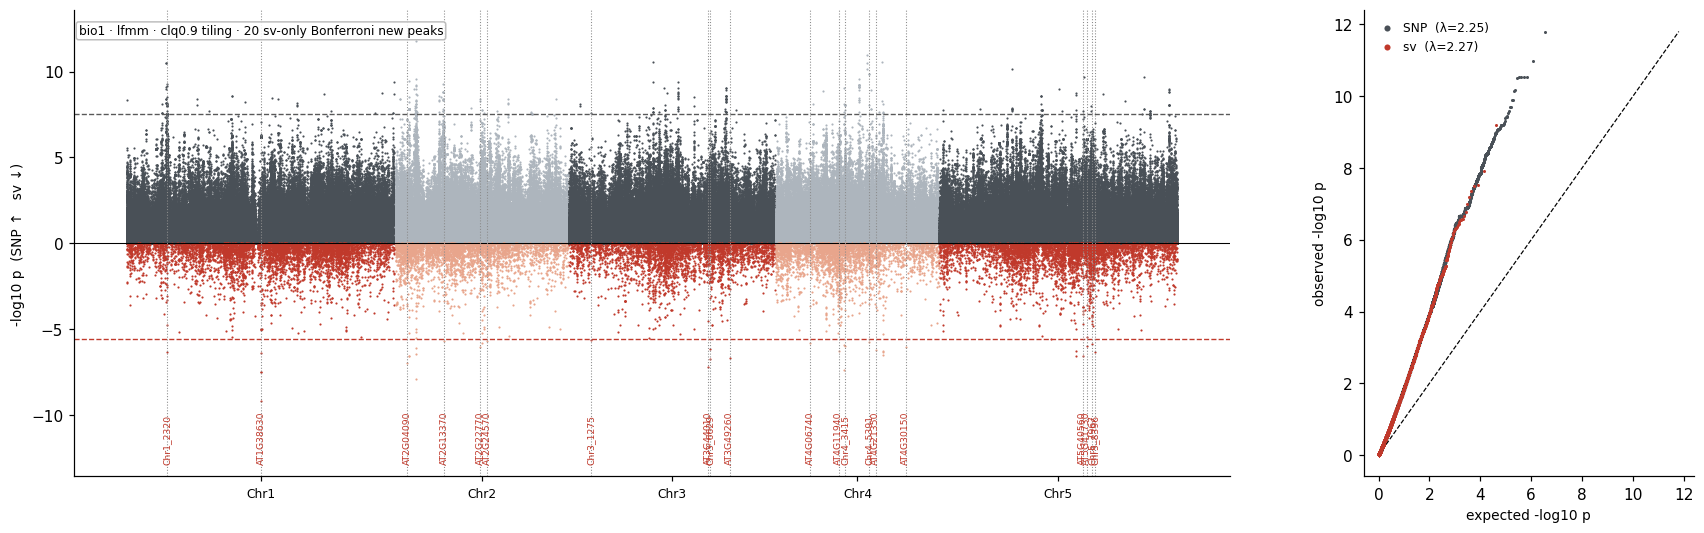

bio1: 20 sv-only Bonferroni new peaks (gene-bearing: 13)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
1779,Chr1_7218,Chr1,15244709,AT1G38630;AT1G38790;AT1G38950;AT1G40083;AT1G40...,9.205129,7.050125
4792,Chr3_6523,Chr3,15800734,AT3G44010,7.191515,1.583645
3732,Chr2_825,Chr2,1364859,AT2G04090;AT2G04100,7.001303,7.265728
4812,Chr3_6629,Chr3,16026789,,6.773037,5.765023
5046,Chr3_8038,Chr3,18267606,AT3G49260;AT3G49270,6.674608,6.507199
8439,Chr5_7144,Chr5,16246543,AT5G40560;AT5G40570,6.550867,4.872338
968,Chr1_2320,Chr1,4583448,,6.347843,5.414074
8659,Chr5_8396,Chr5,17646009,,6.338203,4.605764
5800,Chr4_2893,Chr4,7170249,AT4G11940;AT4G11950,6.299190,6.071849
6292,Chr4_5842,Chr4,11364138,AT4G21350;AT4G21366;AT4G21380,6.242704,4.410923


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


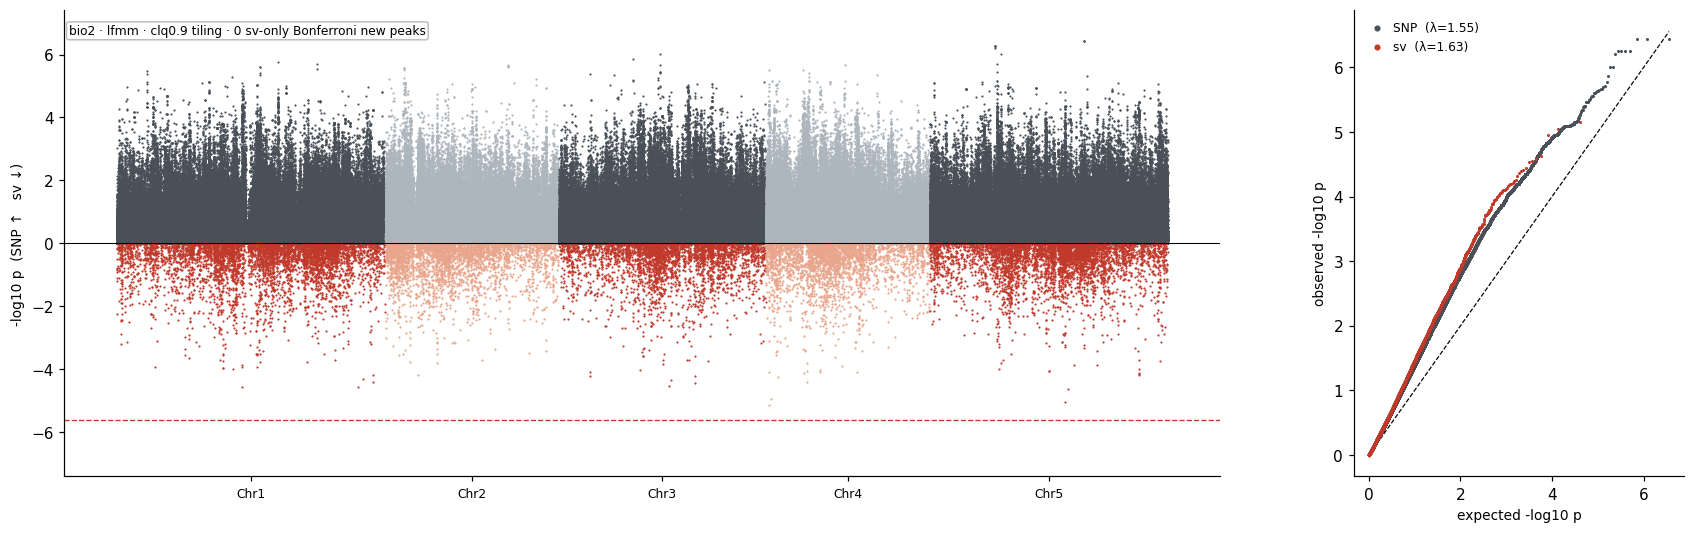

bio2: 0 sv-only Bonferroni new peaks (gene-bearing: 0)


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


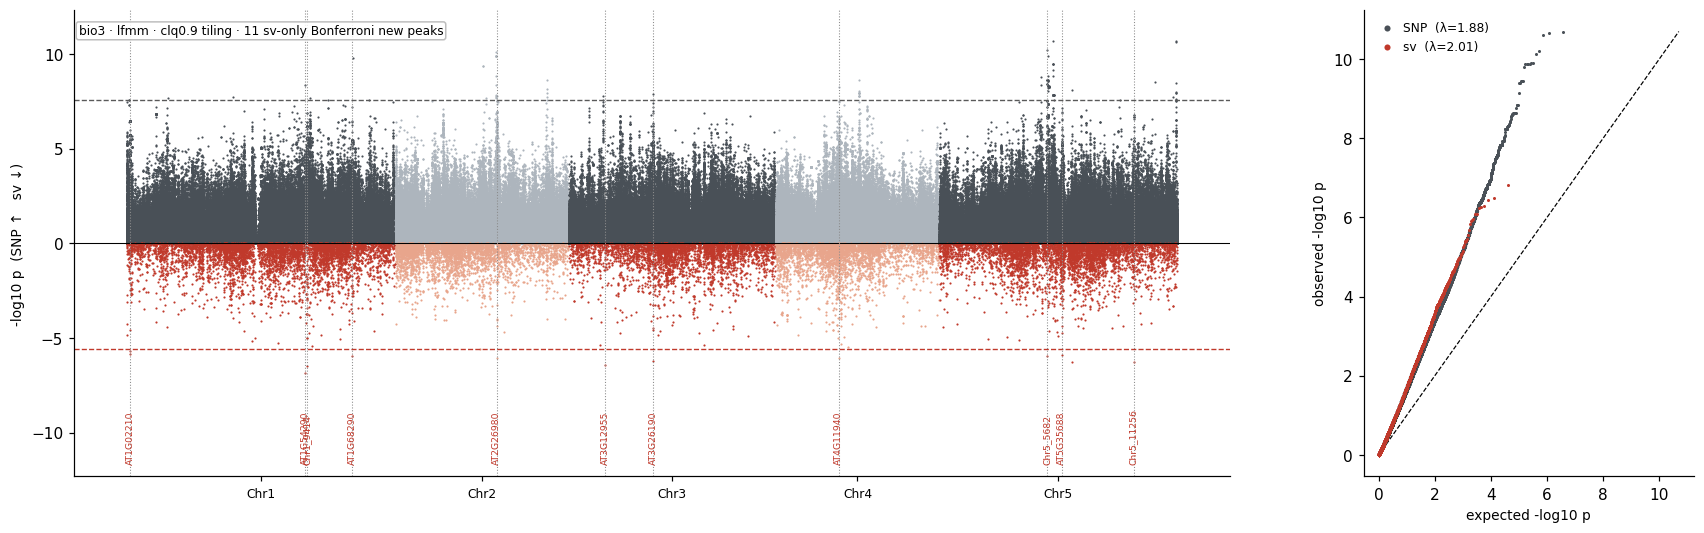

bio3: 11 sv-only Bonferroni new peaks (gene-bearing: 8)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
2251,Chr1_9353,Chr1,20268185,AT1G54290;AT1G54300;AT1G54310;AT1G54320;AT1G54...,6.824221,4.613486
2264,Chr1_9414,Chr1,20498951,,6.484214,6.856608
4014,Chr3_1988,Chr3,4136109,AT3G12955;AT3G12960,6.439403,1.529649
6989,Chr5_11256,Chr5,22020973,,6.254277,6.162828
4415,Chr3_5065,Chr3,9588775,AT3G26190,6.238682,5.678791
5800,Chr4_2893,Chr4,7170249,AT4G11940;AT4G11950,6.078094,6.659100
3163,Chr2_4314,Chr2,11519010,AT2G26980;AT2G26990,6.074911,6.396711
8059,Chr5_5682,Chr5,12191717,,5.958918,6.128437
517,Chr1_13098,Chr1,25602577,AT1G68290;AT1G68300;AT1G68310,5.943260,5.443268
8144,Chr5_5964,Chr5,13863725,AT5G35688,5.903805,4.227032


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


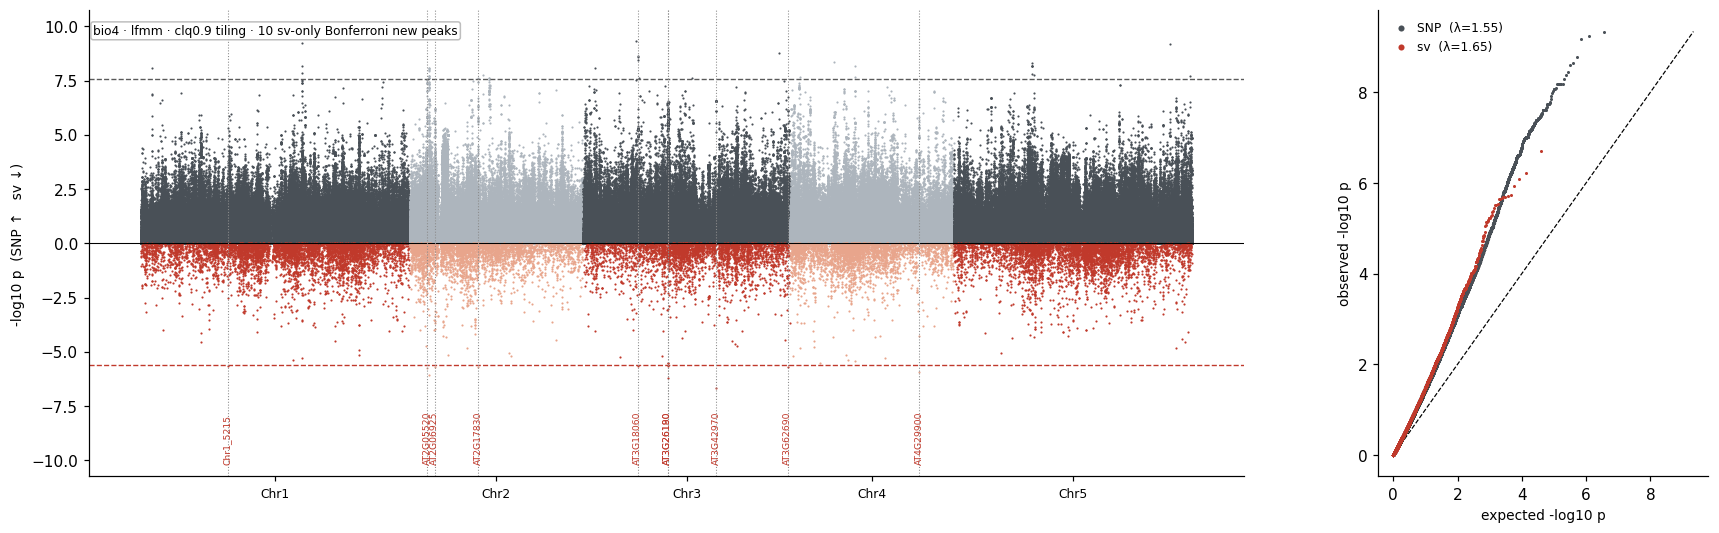

bio4: 10 sv-only Bonferroni new peaks (gene-bearing: 9)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
4745,Chr3_6345,Chr3,15053578,AT3G42970;AT3G42990,6.693105,6.576840
4414,Chr3_5063,Chr3,9582038,AT3G26180;AT3G26190,6.225077,6.189910
6523,Chr4_7483,Chr4,14620679,AT4G29900,5.936775,5.445739
2400,Chr2_1079,Chr2,2018367,AT2G05520,5.736373,7.529699
3884,Chr3_10559,Chr3,23184296,AT3G62690,5.711959,2.543017
2455,Chr2_1236,Chr2,2858592,AT2G06925;AT2G06960,5.697968,6.194949
2784,Chr2_2409,Chr2,7758344,AT2G17830;AT2G17840;AT2G17845;AT2G17850,5.692494,6.339544
1372,Chr1_5215,Chr1,9795165,,5.655084,5.316579
4415,Chr3_5065,Chr3,9585422,AT3G26190,5.647788,5.841559
4130,Chr3_3033,Chr3,6187105,AT3G18060;AT3G18070,5.639209,6.183719


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


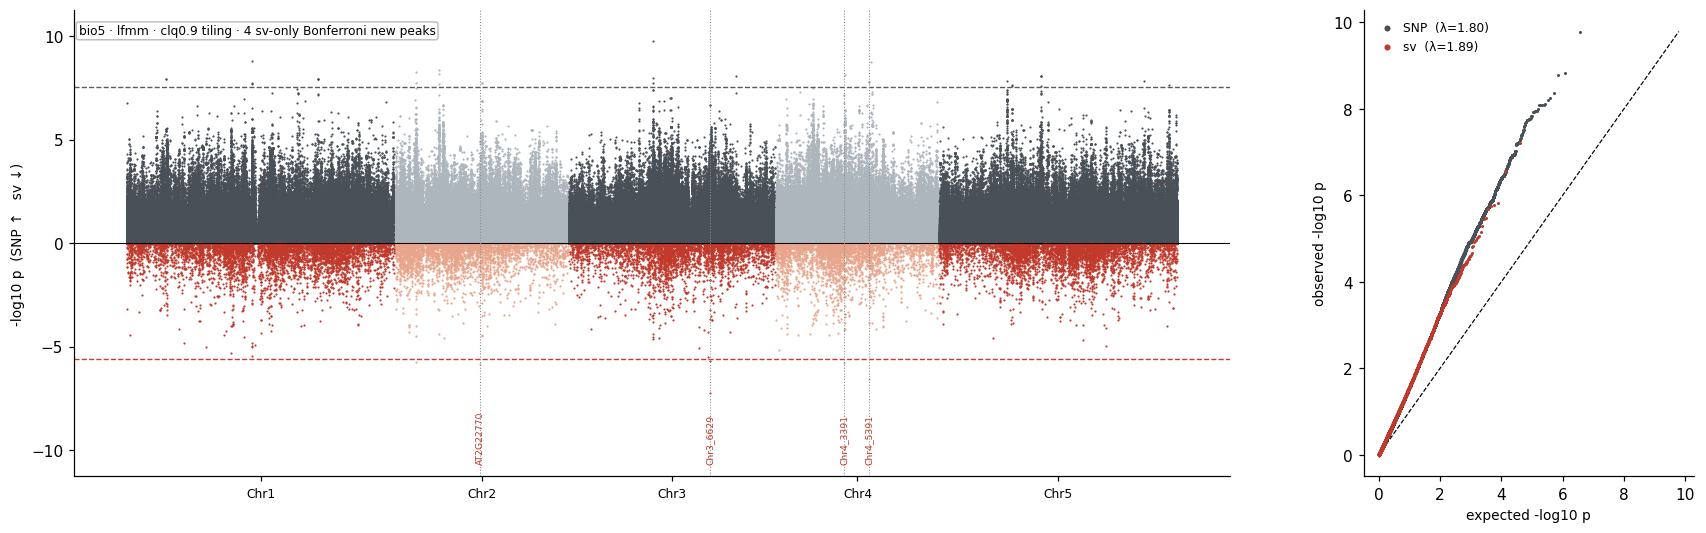

bio5: 4 sv-only Bonferroni new peaks (gene-bearing: 1)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
4812,Chr3_6629,Chr3,16026789,,7.215842,6.700987
6214,Chr4_5391,Chr4,10609384,,6.559879,4.732896
2986,Chr2_3299,Chr2,9686790,AT2G22770,5.827765,1.521228
5900,Chr4_3391,Chr4,7812731,,5.783002,7.187614


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


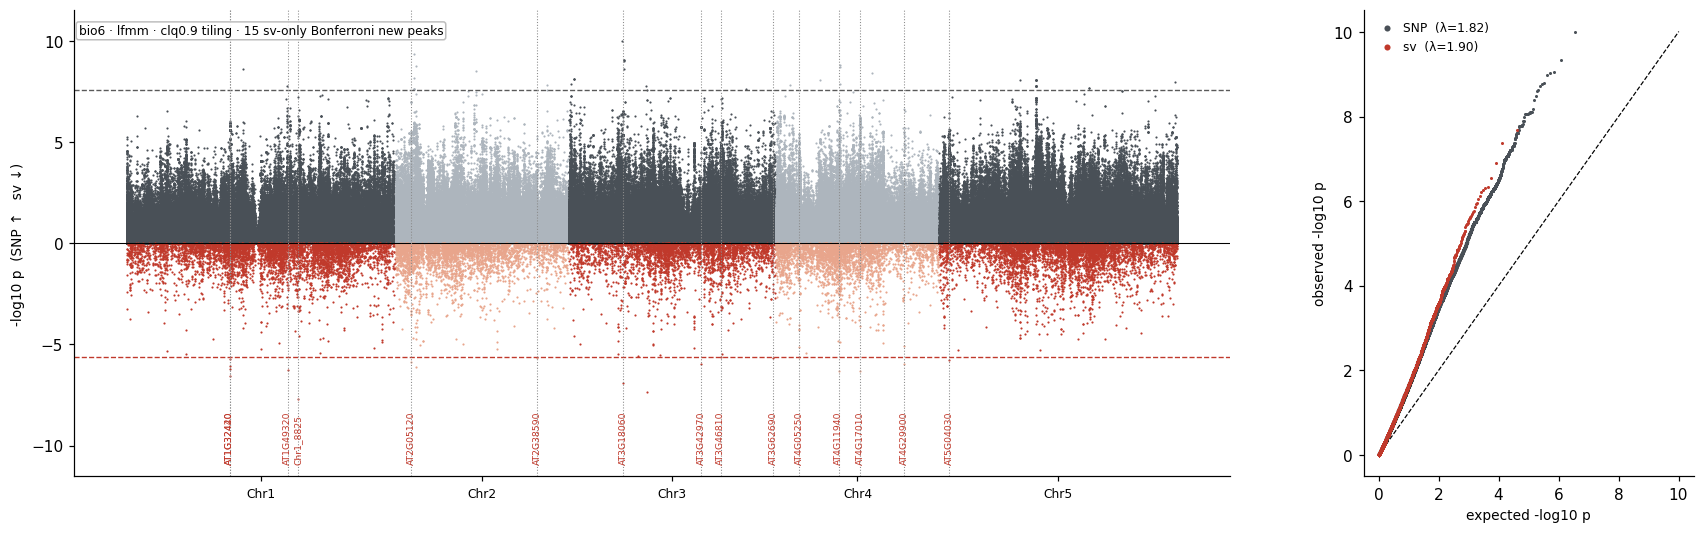

bio6: 15 sv-only Bonferroni new peaks (gene-bearing: 14)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
2159,Chr1_8825,Chr1,19426362,,7.691816,7.228182
4130,Chr3_3033,Chr3,6187105,AT3G18060;AT3G18070,6.913285,6.555253
1568,Chr1_6373,Chr1,11710599,AT1G32440,6.539524,4.932558
5800,Chr4_2893,Chr4,7170249,AT4G11940;AT4G11950,6.322848,6.583019
6100,Chr4_4566,Chr4,9576756,AT4G17010;AT4G17020,6.306391,6.250653
2038,Chr1_8176,Chr1,18249222,AT1G49320;AT1G49330,6.263026,4.369612
1567,Chr1_6372,Chr1,11710502,AT1G32420;AT1G32430,6.216029,6.031029
4745,Chr3_6345,Chr3,15053578,AT3G42970;AT3G42990,5.952282,5.724694
6523,Chr4_7483,Chr4,14620679,AT4G29900,5.943022,5.235165
2382,Chr2_1015,Chr2,1848932,AT2G05120;AT2G05140,5.858232,5.531710


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


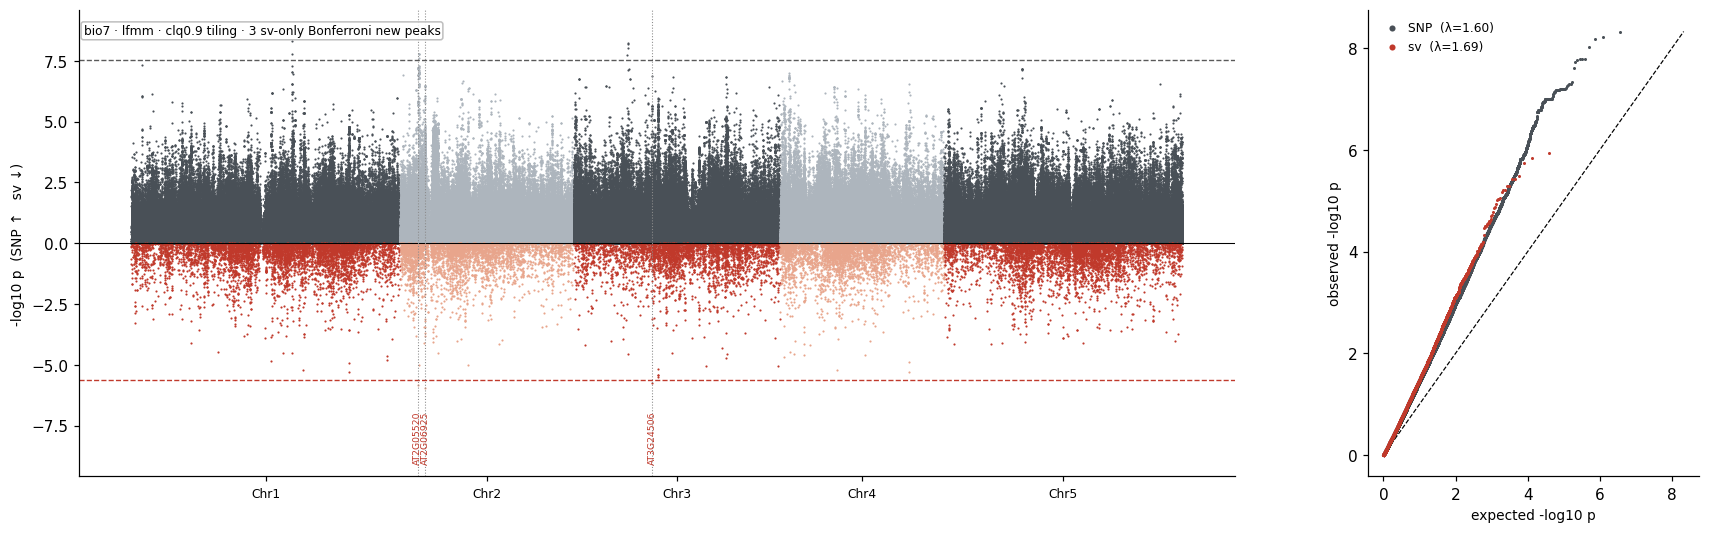

bio7: 3 sv-only Bonferroni new peaks (gene-bearing: 3)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
2455,Chr2_1236,Chr2,2858592,AT2G06925;AT2G06960,5.943355,6.472551
2400,Chr2_1079,Chr2,2018367,AT2G05520,5.846085,7.192655
4326,Chr3_4480,Chr3,8925740,AT3G24506,5.746873,6.857918


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


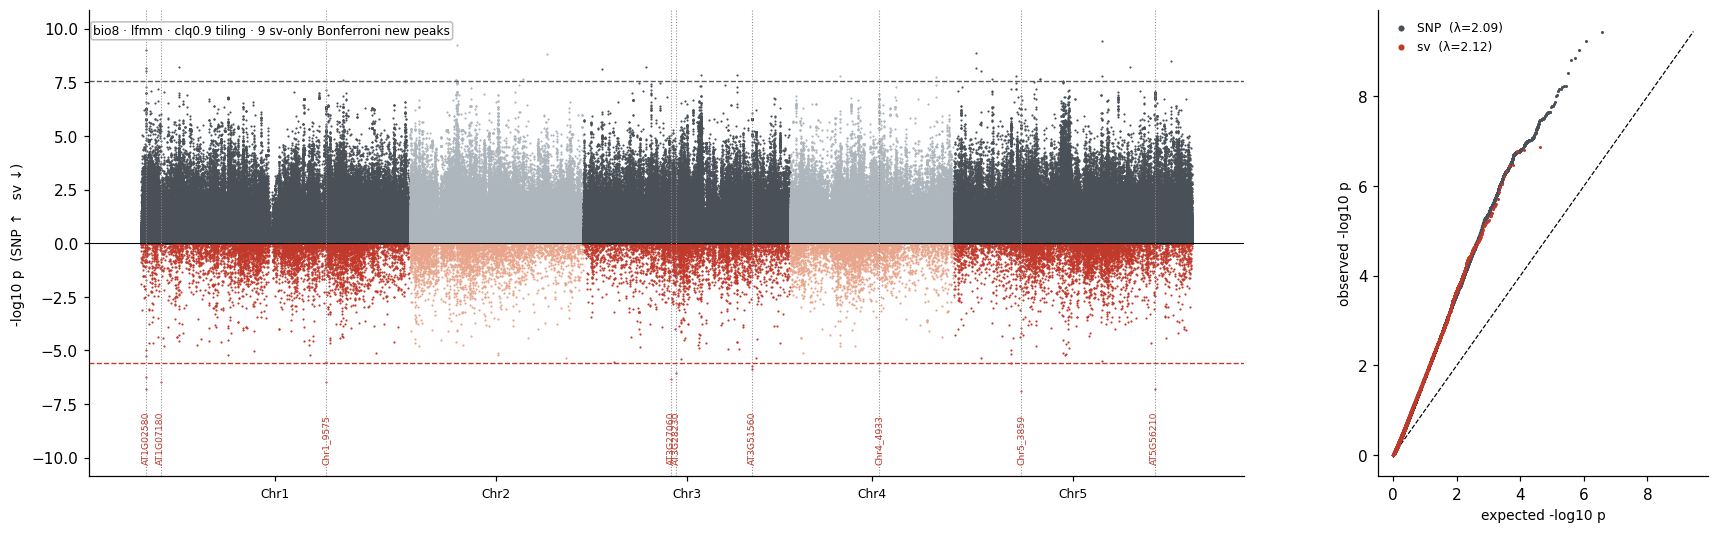

bio8: 9 sv-only Bonferroni new peaks (gene-bearing: 6)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
7647,Chr5_3859,Chr5,7645894,,6.878396,6.508161
7045,Chr5_11729,Chr5,22757963,AT5G56210;AT5G56220,6.812452,7.043332
1098,Chr1_330,Chr1,549566,AT1G02580,6.783398,7.265625
2293,Chr1_9575,Chr1,20913842,,6.466868,7.153522
151,Chr1_1093,Chr1,2213049,AT1G07180;AT1G07190;AT1G07200,6.455343,6.042968
4458,Chr3_5325,Chr3,9982702,AT3G27060,6.330834,3.628201
4538,Chr3_5691,Chr3,10532198,AT3G28230;AT3G28243,6.042271,2.201132
6156,Chr4_4933,Chr4,10112423,,5.967293,6.950283
5133,Chr3_8548,Chr3,19131001,AT3G51560;AT3G51570;AT3G51580,5.858513,5.799033


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


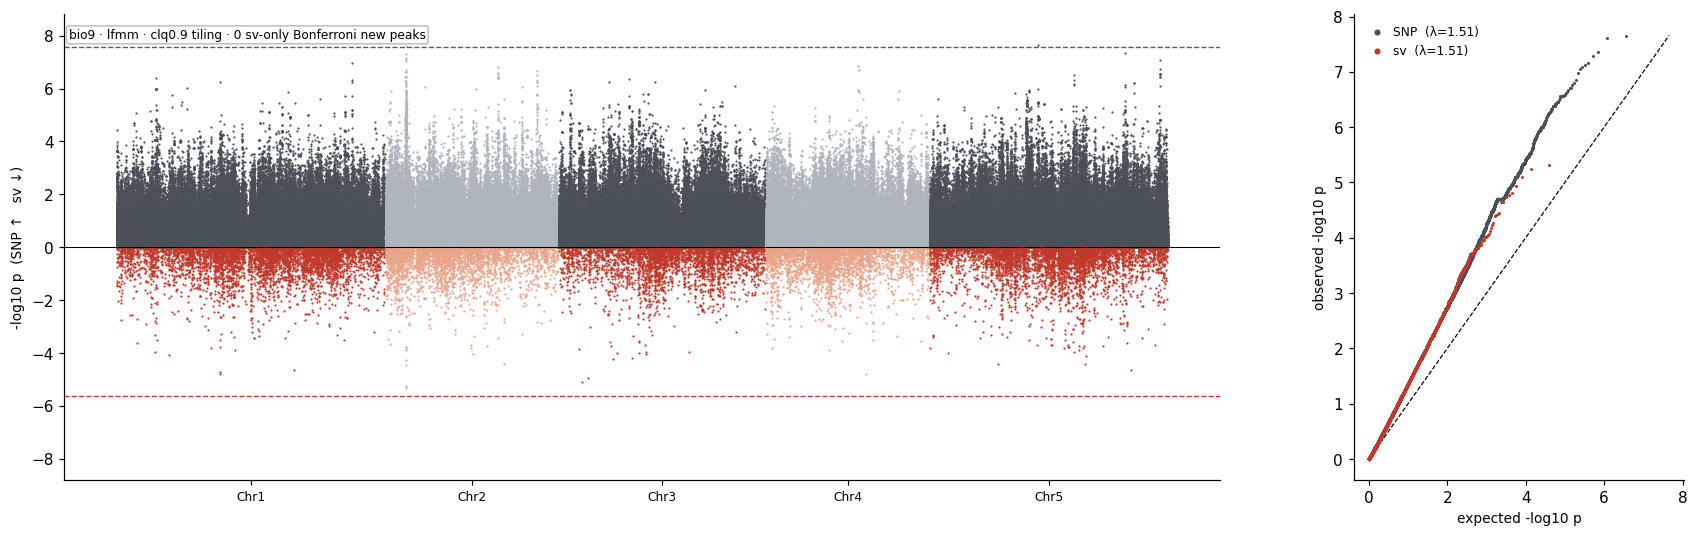

bio9: 0 sv-only Bonferroni new peaks (gene-bearing: 0)


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


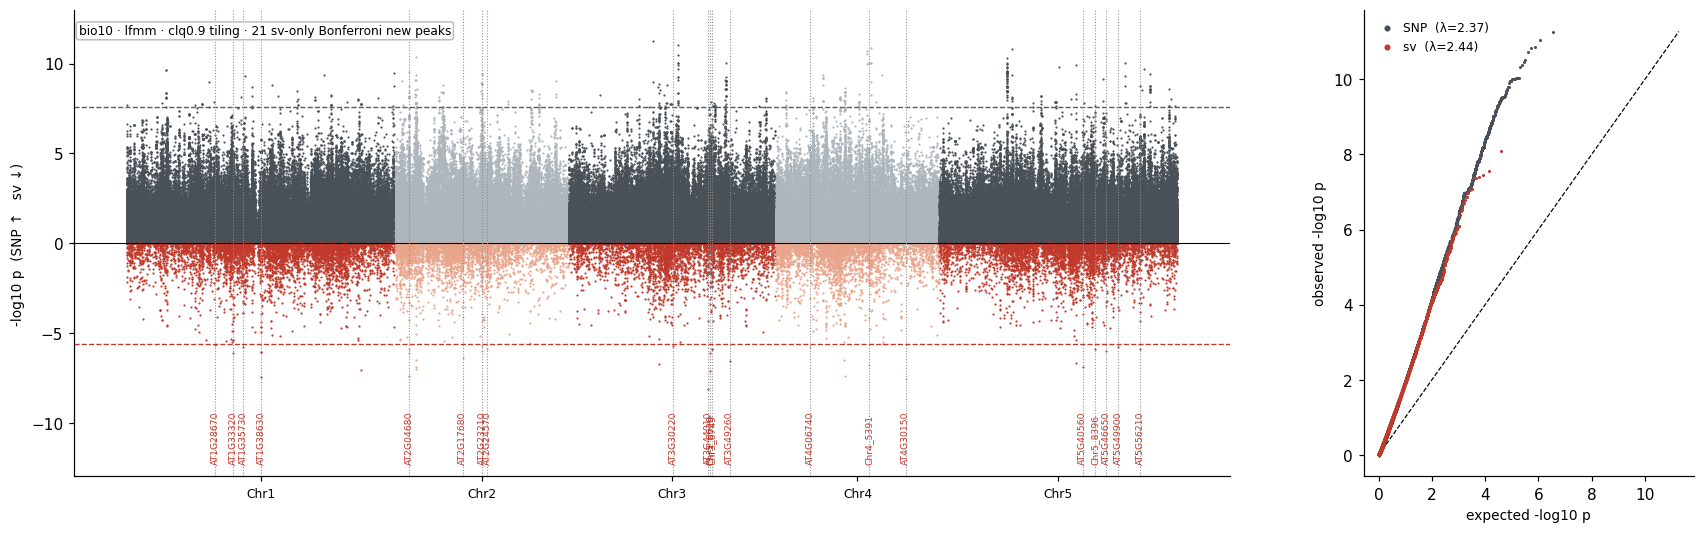

bio10: 21 sv-only Bonferroni new peaks (gene-bearing: 17)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
4792,Chr3_6523,Chr3,15800734,AT3G44010,8.083709,3.127569
6527,Chr4_7532,Chr4,14741994,AT4G30150,7.565879,2.923449
1779,Chr1_7218,Chr1,15244709,AT1G38630;AT1G38790;AT1G38950;AT1G40083;AT1G40...,7.463471,6.607665
4812,Chr3_6629,Chr3,16026789,,7.079071,7.202691
8439,Chr5_7144,Chr5,16246543,AT5G40560;AT5G40570,6.878364,4.935023
6214,Chr4_5391,Chr4,10609384,,6.787414,4.590103
5046,Chr3_8038,Chr3,18267606,AT3G49260;AT3G49270,6.575516,4.525111
2774,Chr2_2365,Chr2,7680263,AT2G17680;AT2G17690,6.375886,5.905343
1619,Chr1_6605,Chr1,12079628,AT1G33320,6.103185,5.997115
8857,Chr5_9435,Chr5,18931814,AT5G46650;AT5G46660,6.002347,7.220981


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


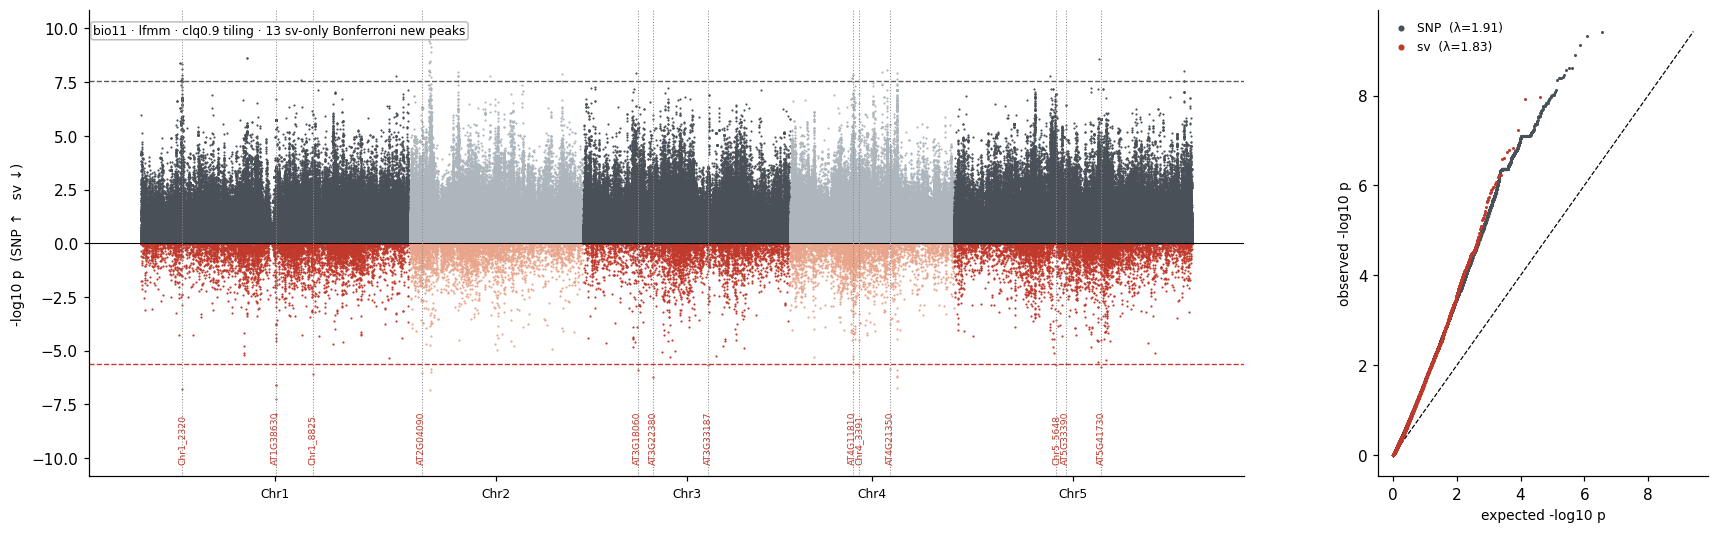

bio11: 13 sv-only Bonferroni new peaks (gene-bearing: 9)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
1779,Chr1_7218,Chr1,15244709,AT1G38630;AT1G38790;AT1G38950;AT1G40083;AT1G40...,7.926687,6.724235
968,Chr1_2320,Chr1,4583448,,6.780791,5.794331
4255,Chr3_3868,Chr3,7922025,AT3G22380,6.234077,5.980707
2159,Chr1_8825,Chr1,19426362,,6.078794,6.018077
3732,Chr2_825,Chr2,1364859,AT2G04090;AT2G04100,6.024987,6.363081
5788,Chr4_2826,Chr4,7102102,AT4G11810,5.976043,5.213811
4130,Chr3_3033,Chr3,6187105,AT3G18060;AT3G18070,5.909664,5.369865
6292,Chr4_5842,Chr4,11364138,AT4G21350;AT4G21366;AT4G21380,5.835549,4.350164
8496,Chr5_7457,Chr5,16688503,AT5G41730;AT5G41740;AT5G41750,5.745343,5.788795
5900,Chr4_3391,Chr4,7812731,,5.720982,6.006425


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


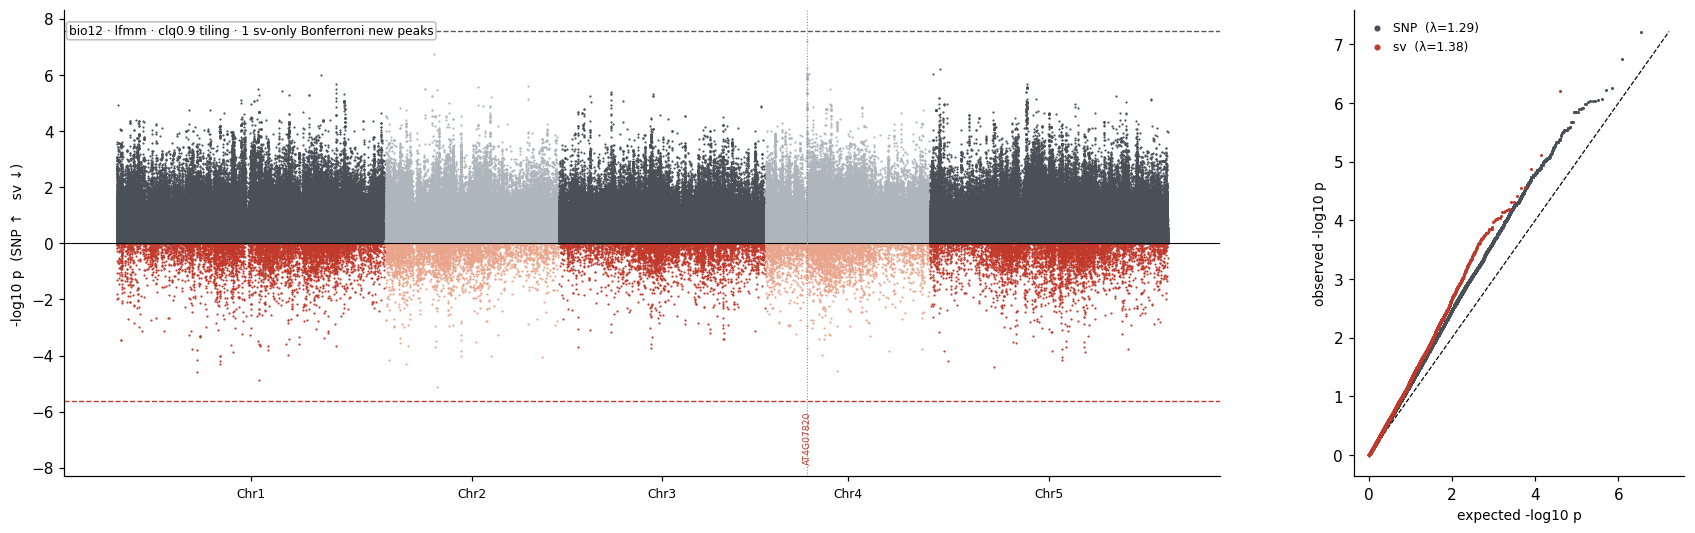

bio12: 1 sv-only Bonferroni new peaks (gene-bearing: 1)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
5510,Chr4_1721,Chr4,4700985,AT4G07820;AT4G07825;AT4G07868,6.211104,7.217489


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


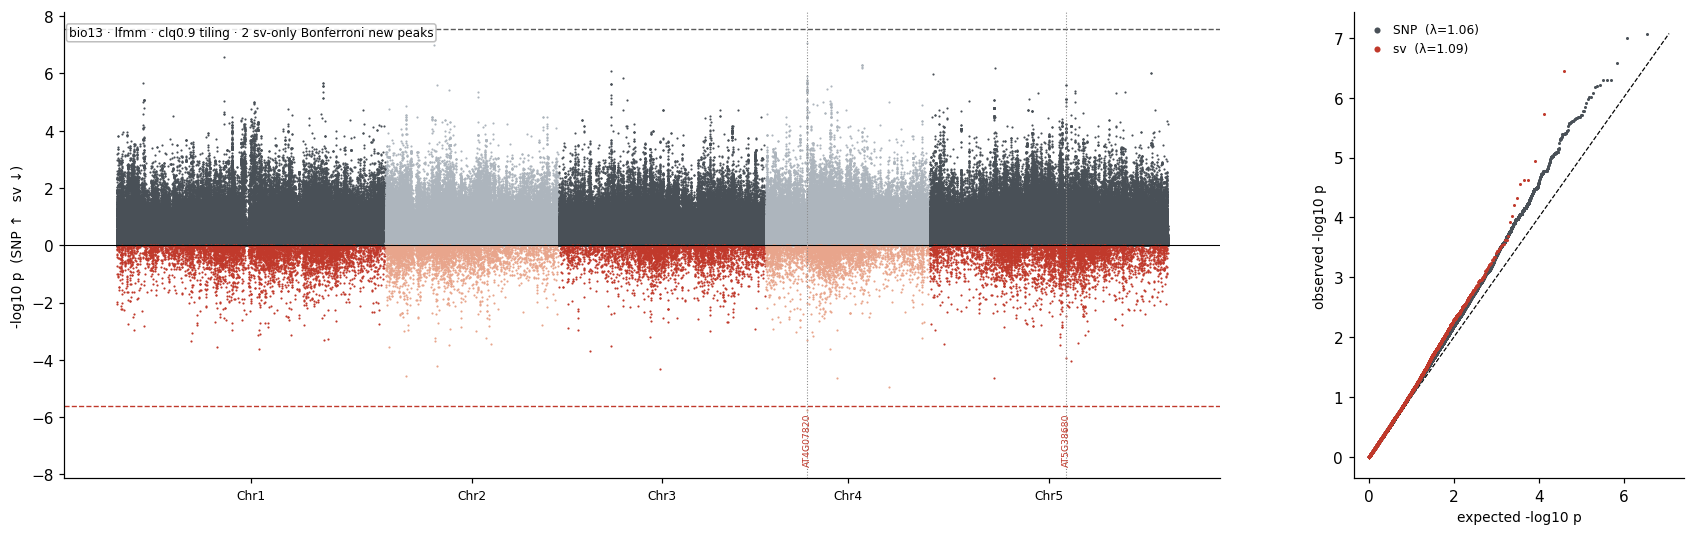

bio13: 2 sv-only Bonferroni new peaks (gene-bearing: 2)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
8329,Chr5_6664,Chr5,15479741,AT5G38680;AT5G38690,6.436489,1.814775
5510,Chr4_1721,Chr4,4700985,AT4G07820;AT4G07825;AT4G07868,5.732821,7.069850


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


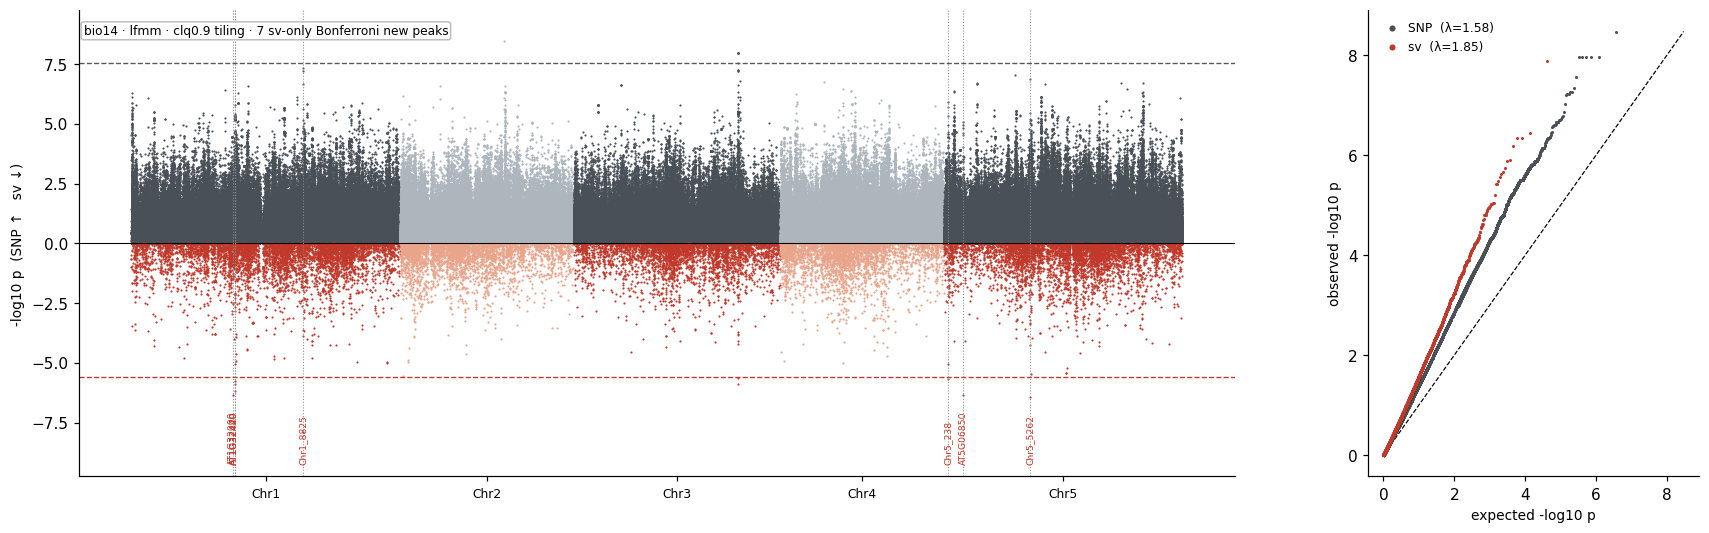

bio14: 7 sv-only Bonferroni new peaks (gene-bearing: 4)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
2159,Chr1_8825,Chr1,19426362,,7.877203,7.340016
7936,Chr5_5262,Chr5,9716672,,6.441828,6.854980
7164,Chr5_1267,Chr5,2131980,AT5G06850;AT5G06860;AT5G06870,6.349956,3.633996
1540,Chr1_6219,Chr1,11502370,AT1G32000;AT1G32010;AT1G32020;AT1G32030;AT1G32050,6.344207,1.970662
1568,Chr1_6373,Chr1,11710599,AT1G32440,6.179648,5.786064
1567,Chr1_6372,Chr1,11710502,AT1G32420;AT1G32430,5.886285,5.412347
7442,Chr5_238,Chr5,394192,,5.662876,5.929708


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


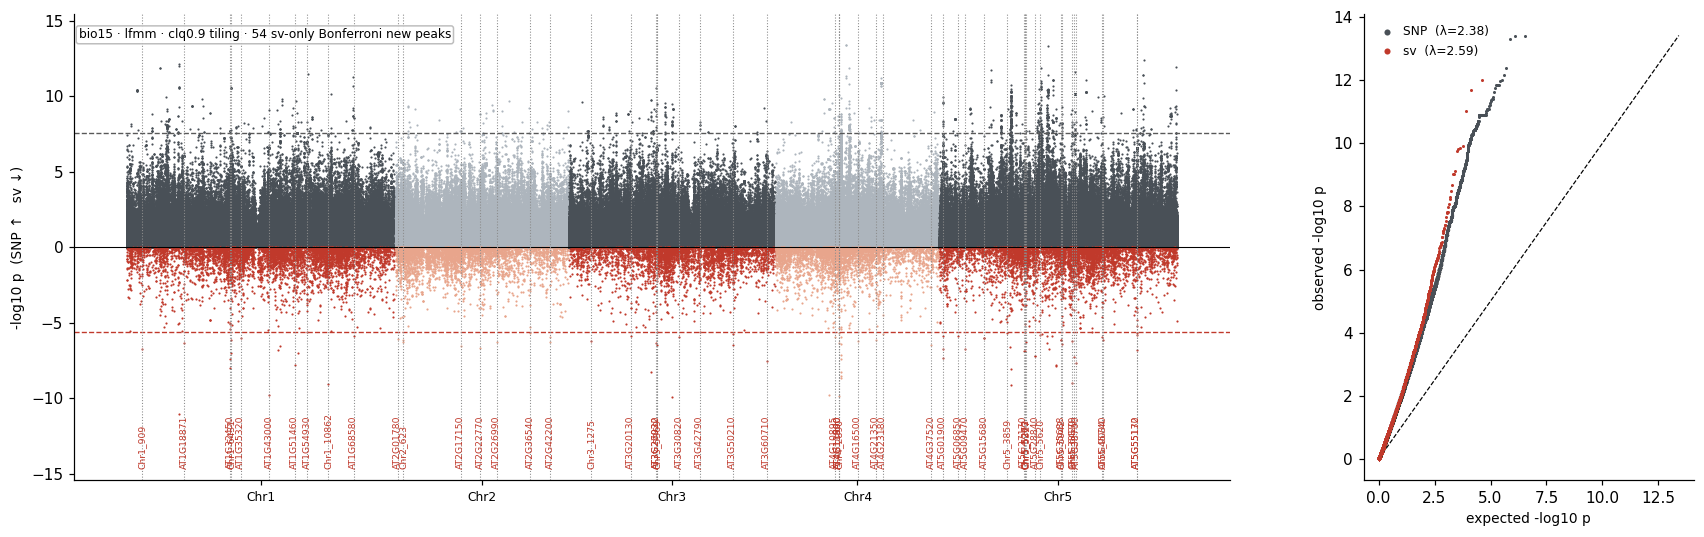

bio15: 54 sv-only Bonferroni new peaks (gene-bearing: 39)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
5799,Chr4_2890,Chr4,7167024,,9.846716,1.840142
1803,Chr1_7276,Chr1,16145711,AT1G43000;AT1G43005,9.809510,5.110037
139,Chr1_10862,Chr1,22828003,,9.030576,7.499218
1570,Chr1_6382,Chr1,11720322,AT1G32450,7.976471,6.717811
2122,Chr1_8612,Chr1,19084053,AT1G51460,7.774514,7.350850
8332,Chr5_6670,Chr5,15490812,AT5G38700;AT5G38710,7.648938,6.411324
3841,Chr3_10239,Chr3,22439359,AT3G60710,7.534967,6.365900
8294,Chr5_6530,Chr5,15250048,AT5G38170;AT5G38180;AT5G38190;AT5G38195;AT5G38197,7.292960,6.517332
8007,Chr5_5508,Chr5,10875575,AT5G28840,7.223308,6.677557
1581,Chr1_6431,Chr1,11819850,,7.020814,6.157861


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


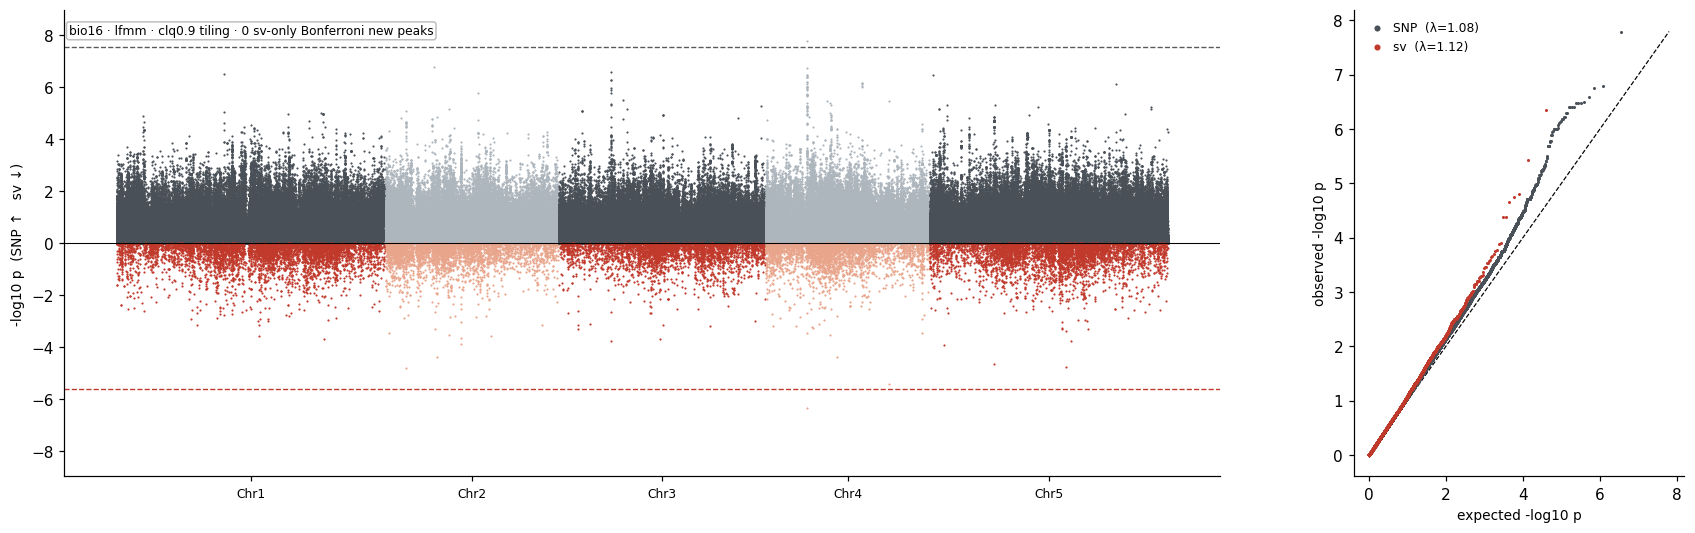

bio16: 0 sv-only Bonferroni new peaks (gene-bearing: 0)


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


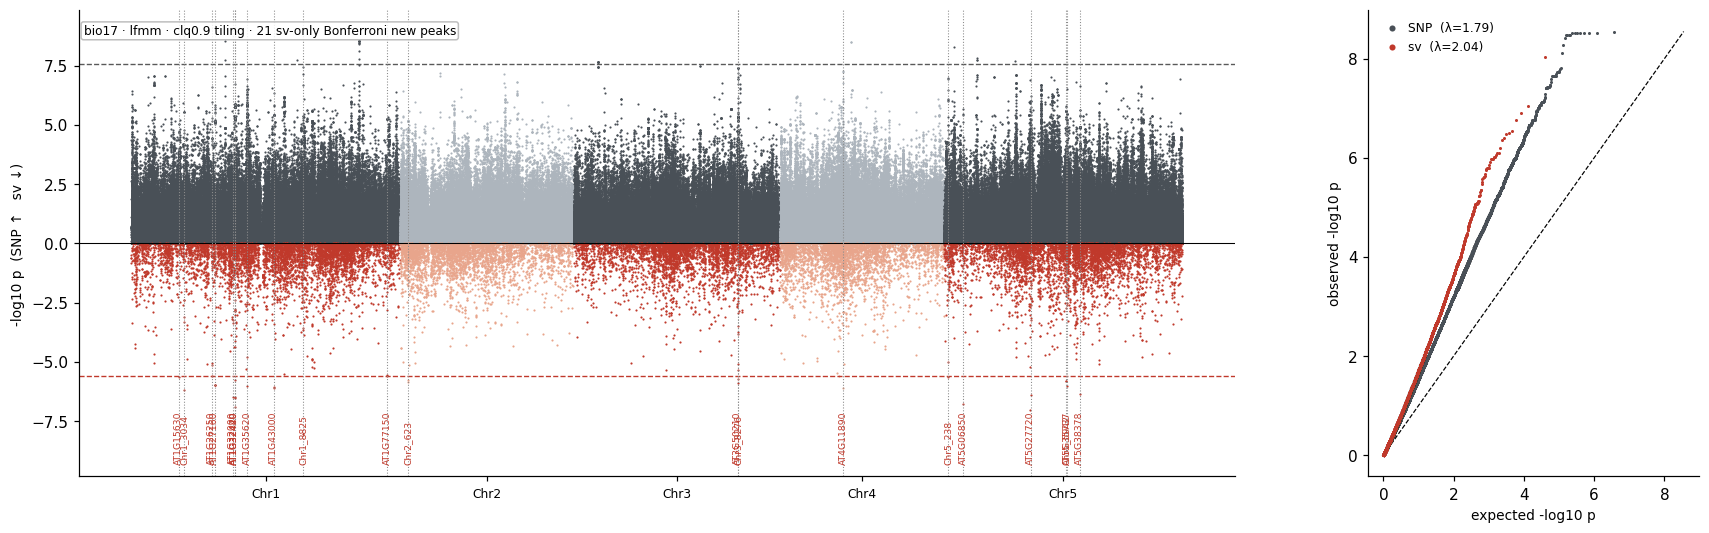

bio17: 21 sv-only Bonferroni new peaks (gene-bearing: 15)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
2159,Chr1_8825,Chr1,19426362,,8.033710,7.441969
1568,Chr1_6373,Chr1,11710599,AT1G32440,6.903784,6.719418
7164,Chr5_1267,Chr5,2131980,AT5G06850;AT5G06860;AT5G06870,6.770314,3.941400
1567,Chr1_6372,Chr1,11710502,AT1G32420;AT1G32430,6.546738,5.862358
1540,Chr1_6219,Chr1,11502370,AT1G32000;AT1G32010;AT1G32020;AT1G32030;AT1G32050,6.493132,2.450378
7946,Chr5_5310,Chr5,9817738,AT5G27720,6.390972,5.997626
8313,Chr5_6596,Chr5,15340885,AT5G38378;AT5G38380,6.355898,4.918432
1055,Chr1_3034,Chr1,5929272,,6.192201,5.560131
5795,Chr4_2865,Chr4,7149993,AT4G11890;AT4G11900,6.091758,6.979183
1803,Chr1_7276,Chr1,16144008,AT1G43000;AT1G43005,6.090890,6.334590


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


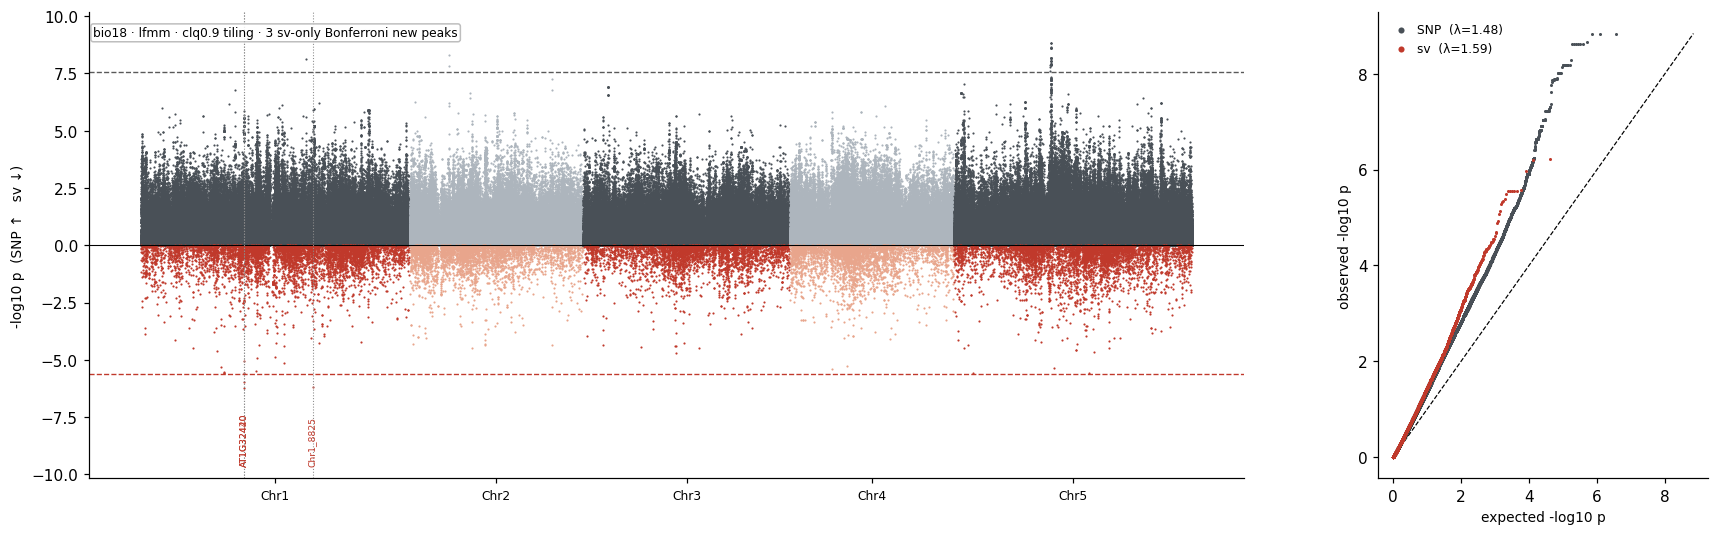

bio18: 3 sv-only Bonferroni new peaks (gene-bearing: 2)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
1568,Chr1_6373,Chr1,11710599,AT1G32440,6.218274,5.840490
2159,Chr1_8825,Chr1,19426362,,6.189161,5.894356
1567,Chr1_6372,Chr1,11710502,AT1G32420;AT1G32430,5.970880,5.693578


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


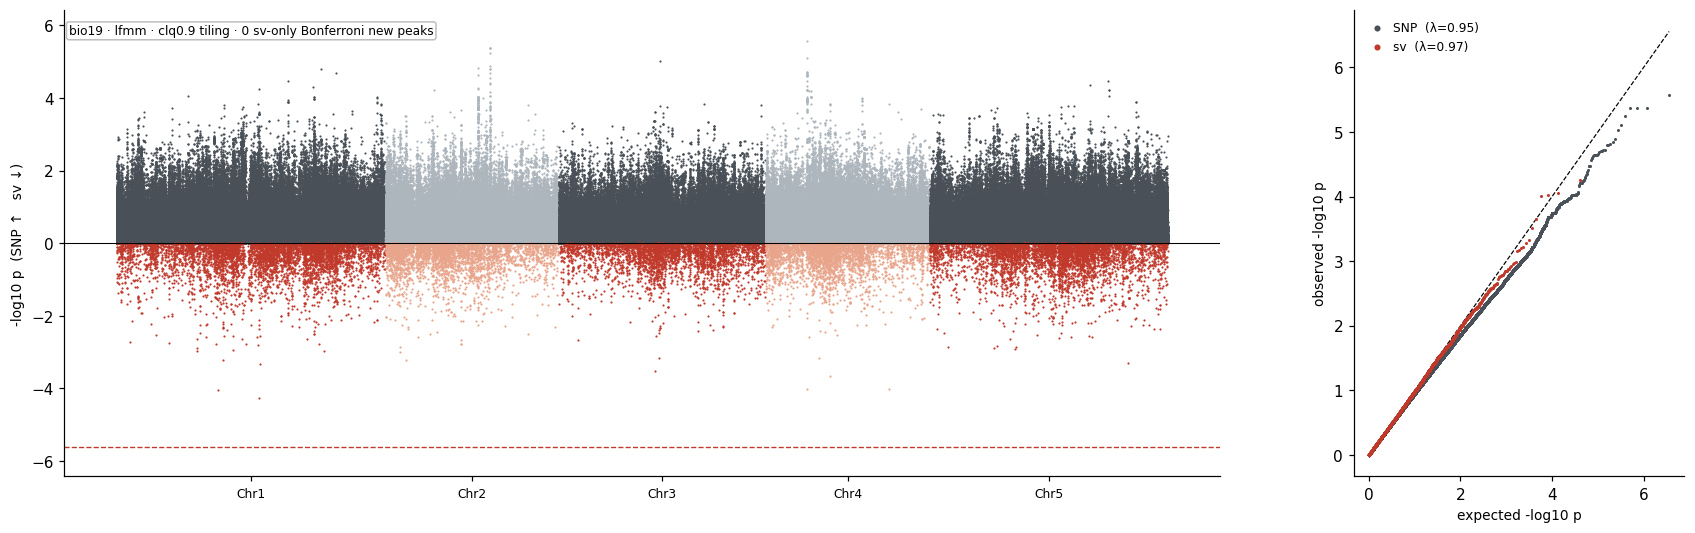

bio19: 0 sv-only Bonferroni new peaks (gene-bearing: 0)


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


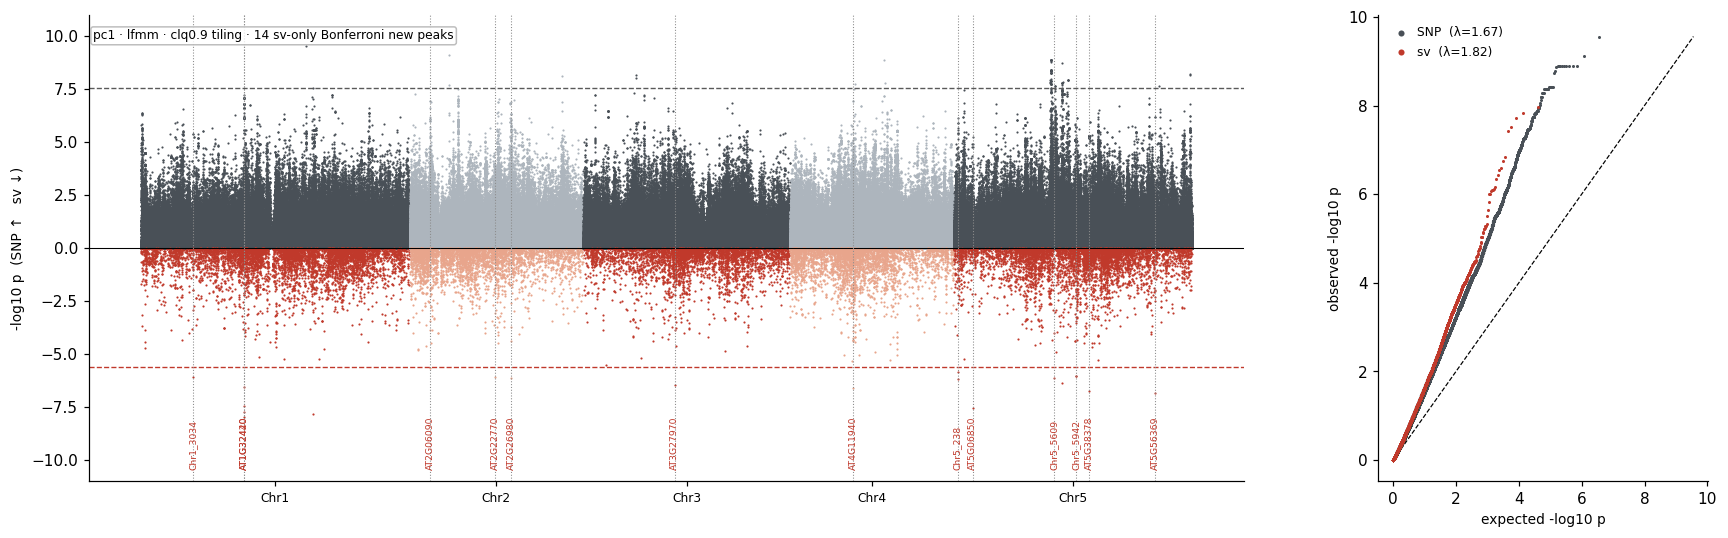

pc1: 14 sv-only Bonferroni new peaks (gene-bearing: 10)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
1568,Chr1_6373,Chr1,11710599,AT1G32440,7.972136,6.391241
1567,Chr1_6372,Chr1,11710502,AT1G32420;AT1G32430,7.715251,7.228487
7164,Chr5_1267,Chr5,2131980,AT5G06850;AT5G06860;AT5G06870,7.518116,2.450909
7053,Chr5_11773,Chr5,22840707,AT5G56369;AT5G56370;AT5G56380;AT5G56390,6.835593,6.172177
8313,Chr5_6596,Chr5,15340885,AT5G38378;AT5G38380,6.748676,5.274727
5800,Chr4_2893,Chr4,7170249,AT4G11940;AT4G11950,6.582652,6.943992
4509,Chr3_5574,Chr3,10392193,AT3G27970,6.432646,5.526039
7442,Chr5_238,Chr5,394192,,6.149821,5.697607
8037,Chr5_5609,Chr5,11375842,,6.121082,5.712617
3163,Chr2_4314,Chr2,11519010,AT2G26980;AT2G26990,6.099849,5.799273


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


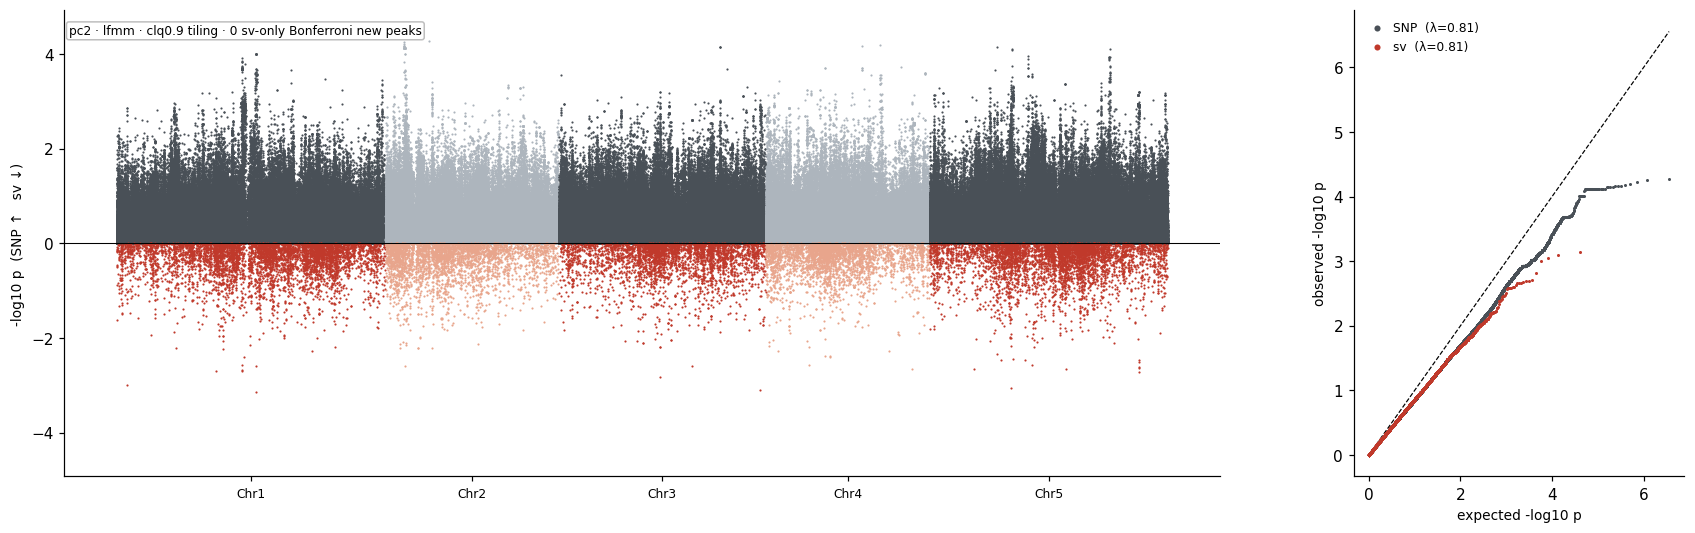

pc2: 0 sv-only Bonferroni new peaks (gene-bearing: 0)


/tmp/ipykernel_1972375/2332778260.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


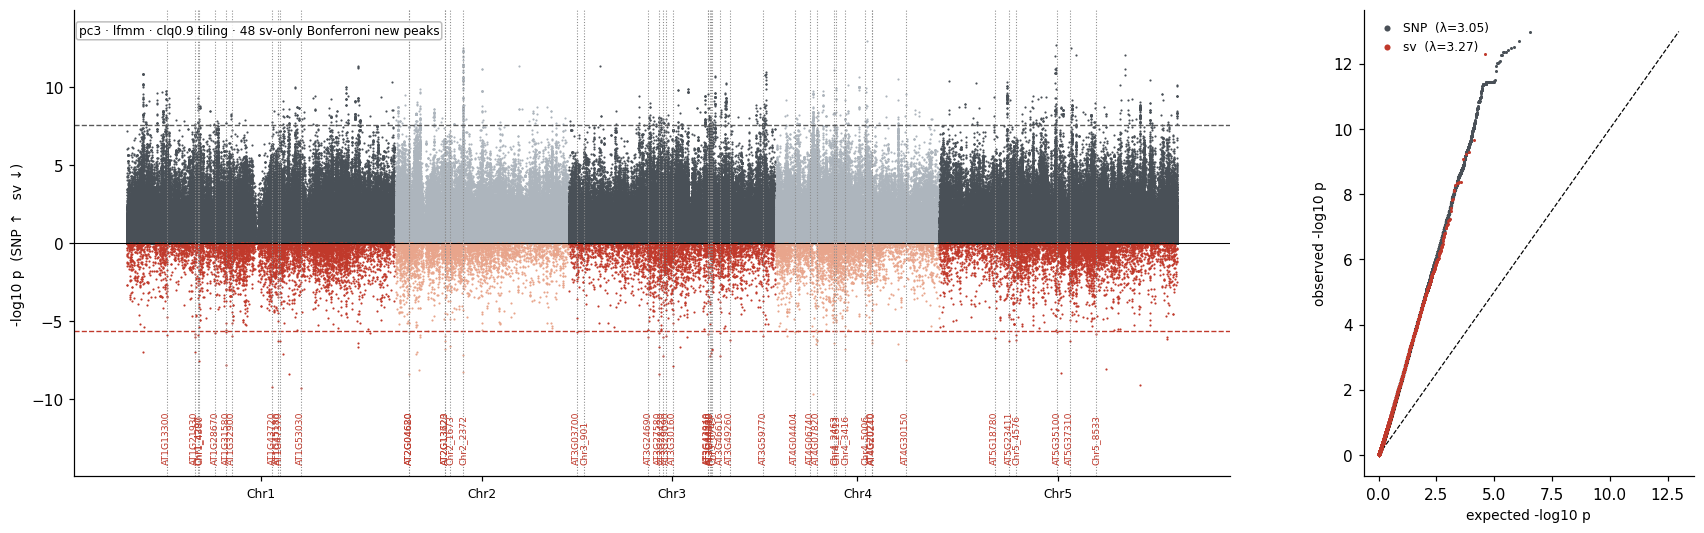

pc3: 48 sv-only Bonferroni new peaks (gene-bearing: 36)


,block,chrom,pos,genes,sv_nlp,snp_nlp_here
4792,Chr3_6523,Chr3,15800734,AT3G44010,12.291334,3.636378
2199,Chr1_9015,Chr1,19763050,AT1G53030;AT1G53035,9.304001,4.268662
1829,Chr1_7356,Chr1,16538665,AT1G43720;AT1G43722;AT1G43730;AT1G43760;AT1G43770,9.229552,7.460754
3785,Chr2_959,Chr2,1642522,AT2G04680;AT2G04690,8.353524,7.456647
4654,Chr3_6092,Chr3,11787287,AT3G30160,7.847669,6.025893
1516,Chr1_6082,Chr1,11321620,AT1G31580;AT1G31600;AT1G31620;AT1G31630;AT1G31640,7.818710,6.205892
1241,Chr1_4380,Chr1,8224955,,7.572489,5.935890
6527,Chr4_7532,Chr4,14741994,AT4G30150,7.485077,2.403331
4814,Chr3_6633,Chr3,16030166,AT3G44370,7.234990,6.935958
4546,Chr3_5739,Chr3,10652790,AT3G28420,7.220046,6.398378


In [2]:
from scipy import stats

def load_raw(cls, axis):
    f = f"{WZAIN}/{MODEL}_{cls}_gen9_{axis}.csv"
    if not os.path.exists(f): return None
    d = pd.read_csv(f)
    d = d[d["MAF"] > 0.05].copy()
    d["nlp"] = -np.log10(d["pval"].clip(lower=1e-300))
    d["gpos"] = d["chrom"].map(OFF) + d["pos"]
    return d

def leads(d):
    d = d[d["block"].notna() & (d["block"] != "")]
    return d.loc[d.groupby("block")["nlp"].idxmax()]

def gif_lambda(p):
    # genomic inflation factor: median observed chi2(1df) / expected median (0.4549)
    p = np.clip(np.asarray(p, float), 1e-300, 1.0)
    chi2 = stats.chi2.isf(p, 1)
    return float(np.median(chi2) / stats.chi2.isf(0.5, 1))

def qq_xy(p, keep_head=15000, n_bulk=3000):
    # observed vs expected -log10p under the uniform null; thin the dense bulk but
    # keep the whole significant tail (small p). Returns (expected, observed).
    p = np.sort(np.clip(np.asarray(p, float)[np.isfinite(p)], 1e-300, 1.0))
    n = len(p)
    exp = -np.log10((np.arange(n) + 0.5) / n)
    obs = -np.log10(p)
    if n <= keep_head + n_bulk:
        idx = np.arange(n)
    else:
        head = np.arange(keep_head)                                   # strongest hits, kept in full
        bulk = np.unique(np.geomspace(keep_head, n - 1, n_bulk).astype(int))
        idx = np.concatenate([head, bulk])
    return exp[idx], obs[idx]

def raw_mirror(ax, axis, cls, s, c):
    bonf_s, bonf_c = -np.log10(0.05/len(s)), -np.log10(0.05/len(c))
    ls_, lc_ = leads(s), leads(c)
    m = lc_.merge(ls_[["block", "nlp"]], on="block", suffixes=("", "_snp"), how="left")
    m["nlp_snp"] = m["nlp_snp"].fillna(0.0)
    newpk = m[(m["nlp"] > bonf_c) & (m["nlp_snp"] <= bonf_s)].copy()
    for i, ch in enumerate(CH):
        ss, cc = s[s.chrom == ch], c[c.chrom == ch]
        ax.scatter(ss.gpos, ss.nlp, s=2, c=(SNP_DARK if i % 2 == 0 else SNP_LIGHT), rasterized=True, linewidths=0)
        ax.scatter(cc.gpos, -cc.nlp, s=2, c=(CLS_DARK if i % 2 == 0 else CLS_LIGHT), rasterized=True, linewidths=0)
    ax.axhline(0, c="k", lw=.7)
    ax.axhline(bonf_s, ls="--", c="0.35", lw=.9)
    ax.axhline(-bonf_c, ls="--", c=CLS_DARK, lw=.9)
    ymax = max(s.nlp.max(), c.nlp.max()) * 1.15
    newpk["genes"] = newpk["block"].map(lambda b: ";".join(genes_on(b)))
    for _, r in newpk.iterrows():
        lab = r.genes.split(";")[0] if r.genes else r.block
        ax.axvline(r.gpos, ls=":", c="0.55", lw=.7)
        ax.annotate(lab, xy=(r.gpos, -ymax*0.95), ha="center", va="bottom", fontsize=6,
                    color=CLS_DARK, rotation=90)
    ax.set_ylim(-ymax, ymax)
    ax.set_xticks([OFF[c]+CHROM_LEN[c]/2 for c in CH]); ax.set_xticklabels(CH, fontsize=8)
    ax.set_ylabel(f"-log10 p  (SNP \u2191   {cls} \u2193)", fontsize=9)
    ax.annotate(f"{axis} \u00b7 lfmm \u00b7 clq0.9 tiling \u00b7 {len(newpk)} {cls}-only Bonferroni new peaks",
                xy=(0.004, 0.97), xycoords="axes fraction", va="top", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=.85))
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    return newpk[["block", "chrom", "pos", "nlp", "nlp_snp", "genes"]].sort_values("nlp", ascending=False)

def qq_panel(ax, cls, s, c):
    lam_s, lam_c = gif_lambda(s["pval"]), gif_lambda(c["pval"])
    xs, ys = qq_xy(s["pval"].to_numpy()); xc, yc = qq_xy(c["pval"].to_numpy())
    hi = max(xs.max(), ys.max(), xc.max(), yc.max())
    ax.plot([0, hi], [0, hi], c="k", lw=.8, ls="--", zorder=1)                 # null diagonal
    ax.scatter(xs, ys, s=4, c=SNP_DARK, rasterized=True, linewidths=0, zorder=2,
               label=f"SNP  (\u03bb={lam_s:.2f})")
    ax.scatter(xc, yc, s=4, c=CLS_DARK, rasterized=True, linewidths=0, zorder=2,
               label=f"{cls}  (\u03bb={lam_c:.2f})")
    ax.set_xlabel("expected -log10 p", fontsize=9)
    ax.set_ylabel("observed -log10 p", fontsize=9)
    ax.legend(loc="upper left", frameon=False, fontsize=8, markerscale=2, handletextpad=0.3)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    return lam_s, lam_c

all_newpk = []
for axis in AXES:
    s, c = load_raw("snp", axis), load_raw(CLS, axis)
    if s is None or c is None:
        print(f"missing {axis}"); continue
    fig = plt.figure(figsize=(19, 5.5))
    gs = fig.add_gridspec(1, 2, width_ratios=[3.5, 1], wspace=0.18)
    newpk = raw_mirror(fig.add_subplot(gs[0]), axis, CLS, s, c)
    qq_panel(fig.add_subplot(gs[1]), CLS, s, c)
    fig.tight_layout(); plt.show()
    newpk = newpk.copy(); newpk["axis"] = axis
    all_newpk.append(newpk)
    print(f"{axis}: {len(newpk)} {CLS}-only Bonferroni new peaks (gene-bearing: {(newpk.genes != '').sum()})")
    if len(newpk):
        display(newpk[["block", "chrom", "pos", "genes", "nlp", "nlp_snp"]].rename(
            columns={"nlp": f"{CLS}_nlp", "nlp_snp": "snp_nlp_here"}))

## Candidate genes — SV-only new peaks, consolidated across all 22 axes

Union of every gene-bearing new peak found above, deduplicated per gene (kept: the
axis with the strongest sv signal), with Ensembl Plants symbol/description and a
recurrence count (how many of the 22 axes flag that gene's block). **Raw, uncalibrated
p — no GIF correction here** (see the `gif_manhattan_snp_vs_sv_lfmm_tile.ipynb` twin
for the inflation-corrected version; the session finding there is that this raw list
collapses almost entirely once genomic inflation is accounted for).

In [3]:
import json, time, urllib.request

ALL = pd.concat(all_newpk, ignore_index=True) if all_newpk else pd.DataFrame(columns=["block","gene","axis","nlp"])
gene_rows = []
for _, r in ALL.iterrows():
    for g in (r.genes.split(";") if r.genes else []):
        gene_rows.append(dict(gene=g, block=r.block, chrom=r.chrom, pos=r.pos, axis=r.axis, nlp=r.nlp))
G = pd.DataFrame(gene_rows)
if len(G):
    recur = G.groupby("gene")["axis"].nunique().rename("n_axes")
    best = G.sort_values("nlp", ascending=False).drop_duplicates("gene").set_index("gene")
    cand = best.join(recur).sort_values("n_axes", ascending=False).reset_index()

    def ensembl_symbols(ids, chunk=900, retries=3):
        out = {}
        for i in range(0, len(ids), chunk):
            sub = ids[i:i + chunk]
            req = urllib.request.Request("https://rest.ensembl.org/lookup/id",
                data=json.dumps({"ids": sub}).encode(),
                headers={"Content-Type": "application/json", "Accept": "application/json"})
            for attempt in range(retries):
                try:
                    with urllib.request.urlopen(req, timeout=60) as r:
                        d = json.load(r)
                    for k, v in d.items():
                        if v:
                            out[k] = (v.get("display_name", "") or "", (v.get("description", "") or "").split(" [Source")[0])
                    break
                except Exception as e:
                    print(f"  [ensembl] chunk {i} attempt {attempt+1}: {e}", flush=True); time.sleep(2)
        return out

    sym = ensembl_symbols(sorted(cand.gene.unique()))
    cand["symbol"] = cand.gene.map(lambda x: sym.get(x, ("", ""))[0])
    cand["description"] = cand.gene.map(lambda x: sym.get(x, ("", ""))[1])
    cand.to_csv(f"{lib.GEA}/r2_gea_nonsnp/phase1_replication/results/multiaxis/raw_manhattan_newpeak_genes_{CLS}_tile.csv", index=False)
    print(f"{len(cand)} unique {CLS}-only new-peak genes across 22 axes")
    display(cand[["gene", "symbol", "description", "block", "chrom", "pos", "n_axes", "nlp"]].head(50))
else:
    print("no gene-bearing new peaks found on any axis")

  [ensembl] chunk 0 attempt 1: HTTP Error 500: Internal Server Error


  [ensembl] chunk 0 attempt 2: HTTP Error 500: Internal Server Error


  [ensembl] chunk 0 attempt 3: HTTP Error 500: Internal Server Error


306 unique sv-only new-peak genes across 22 axes


,gene,symbol,description,block,chrom,pos,n_axes,nlp
0,AT1G32440,,,Chr1_6373,Chr1,11710599,5,7.972136
1,AT1G32420,,,Chr1_6372,Chr1,11710502,5,7.715251
2,AT1G32430,,,Chr1_6372,Chr1,11710502,5,7.715251
3,AT4G11950,,,Chr4_2893,Chr4,7170249,4,6.582652
4,AT5G06850,,,Chr5_1267,Chr5,2131980,4,7.518116
5,AT5G06860,,,Chr5_1267,Chr5,2131980,4,7.518116
6,AT5G06870,,,Chr5_1267,Chr5,2131980,4,7.518116
7,AT4G11940,,,Chr4_2893,Chr4,7170249,4,6.582652
8,AT2G22770,,,Chr2_3299,Chr2,9686790,4,6.670735
9,AT4G07820,,,Chr4_1721,Chr4,4681765,3,6.285120


## Functional theme per gene — stress / climate / flowering / circadian / defense

Same SV-only new-peak gene list, now tagged with a **functional category** via
the project annotator `annotate_genes_tair_uniprot.py` (TAIR GO + UniProt — the mandated
route, *not* ad-hoc Ensembl/mygene). Categories, with the axis each targets:
`flowering` (flowering time, vernalization, photoperiod, **circadian**, meristem identity) ·
`temperature` (cold/freezing/heat, CBF/DREB/COR) · `water` (drought, osmotic, ABA, salinity,
stomata) · `light` (photomorphogenesis, UV, shade avoidance, photosynthesis) · `oxidative`
(ROS, abiotic/general stress response) · `defense` (immunity, pathogen, SA/JA, R-genes) ·
`calcium` (Ca2+/calmodulin/CDPK signalling). A gene can carry several. `categories` empty =
none of the above matched its curated protein name + UniProt FUNCTION/keywords + GO.
Written to `raw_manhattan_newpeak_genes_sv_tile_annotated.csv`. **Raw, uncalibrated p** —
see the GIF twin for the inflation-corrected view.

In [4]:
import importlib.util as _ilu

_annp = os.path.abspath(os.path.join(os.getcwd(), "..", "annotate_genes_tair_uniprot.py"))
_sp = _ilu.spec_from_file_location("ann_tu", _annp)
ann_tu = _ilu.module_from_spec(_sp); _sp.loader.exec_module(ann_tu)

if "cand" in dir() and len(cand):
    _A = ann_tu.annotate(sorted(cand["gene"].unique()))
    _cols = ["gene", "protein_name", "categories", "climate_stress_flowering",
             "uniprot_function", "uniprot_keywords"]
    cand_annot = cand.merge(_A[_cols], on="gene", how="left")
    cand_annot["categories"] = cand_annot["categories"].fillna("")
    _outp = f"{lib.GEA}/r2_gea_nonsnp/phase1_replication/results/multiaxis/raw_manhattan_newpeak_genes_{CLS}_tile_annotated.csv"
    cand_annot.to_csv(_outp, index=False)
    _ntag = int((cand_annot["categories"].str.len() > 0).sum())
    print(f"{len(cand_annot)} genes annotated ; {_ntag} tagged to >=1 climate/stress/flowering/defense category")
    print("\ncategory counts (a gene can carry several):")
    print(cand_annot["categories"].str.split(",").explode().replace("", pd.NA)
          .dropna().value_counts().to_string())
    display(cand_annot[["gene", "symbol", "protein_name", "categories", "n_axes",
                        "nlp", "chrom", "pos"]].sort_values(["n_axes", "nlp"],
                        ascending=False).head(60))
else:
    cand_annot = pd.DataFrame(columns=["gene", "symbol", "categories"])
    print("no genes to annotate")

annotating 306 genes

-- TAIR GAF (GO Consortium) --


GAF cache: /global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection/r2_gea_nonsnp/phase1_replication/results/cache/tair.gaf.gz (7.2 MB)


   GO for 230/306 genes
-- UniProt REST pass 1: reviewed / Swiss-Prot (taxid 3702) --


  uniprot 40/306 -> 24 mapped


  uniprot 80/306 -> 40 mapped


  uniprot 120/306 -> 60 mapped


... (9 outputs left out)

  uniprot 154/154 -> 147 mapped


   UniProt total: 299/306 genes
-- mygene.info (kept for GO term NAMES + entrez) --


306 genes annotated ; 90 tagged to >=1 climate/stress/flowering/defense category

category counts (a gene can carry several):
categories
defense        48
temperature    32
water          21
calcium        11
oxidative      10
flowering       9
light           5


,gene,symbol,protein_name,categories,n_axes,nlp,chrom,pos
0,AT1G32440,,"Plastidial pyruvate kinase 3, chloroplastic (P...",,5,7.972136,Chr1,11710599
1,AT1G32420,,Putative F-box protein At1g32420,,5,7.715251,Chr1,11710502
2,AT1G32430,,Putative F-box/kelch-repeat protein At1g32430,,5,7.715251,Chr1,11710502
4,AT5G06850,,FT-interacting protein 1 (Multiple C2 domain a...,"flowering,calcium",4,7.518116,Chr5,2131980
5,AT5G06860,,Polygalacturonase inhibitor 1 (Polygalacturona...,defense,4,7.518116,Chr5,2131980
6,AT5G06870,,Polygalacturonase inhibitor 2 (Polygalacturona...,defense,4,7.518116,Chr5,2131980
8,AT2G22770,,Transcription factor NAI1 (Basic helix-loop-he...,defense,4,6.670735,Chr2,9686790
3,AT4G11950,,"Transmembrane protein, putative (DUF1191)",,4,6.582652,Chr4,7170249
7,AT4G11940,,Protein ADMETOS,,4,6.582652,Chr4,7170249
21,AT3G44010,,,,3,12.291334,Chr3,15800734


## Dot plot — recurrent SV-only new-peak genes across the 20 climate axes

One dot per (gene, axis) where that gene's block is an sv-only Bonferroni new peak on
that axis. **Dot size** = -log10 p (that axis' sv lead); **color** = functional category
(above). Genes are ordered genomically (chrom then position) and the panel is limited to
genes recurring on **enough axes to stay legible** (auto-threshold, printed below); the
full 347-gene list with categories is the table above. Reading across a row shows how many
of the 20 climate variables independently flag that gene's block.

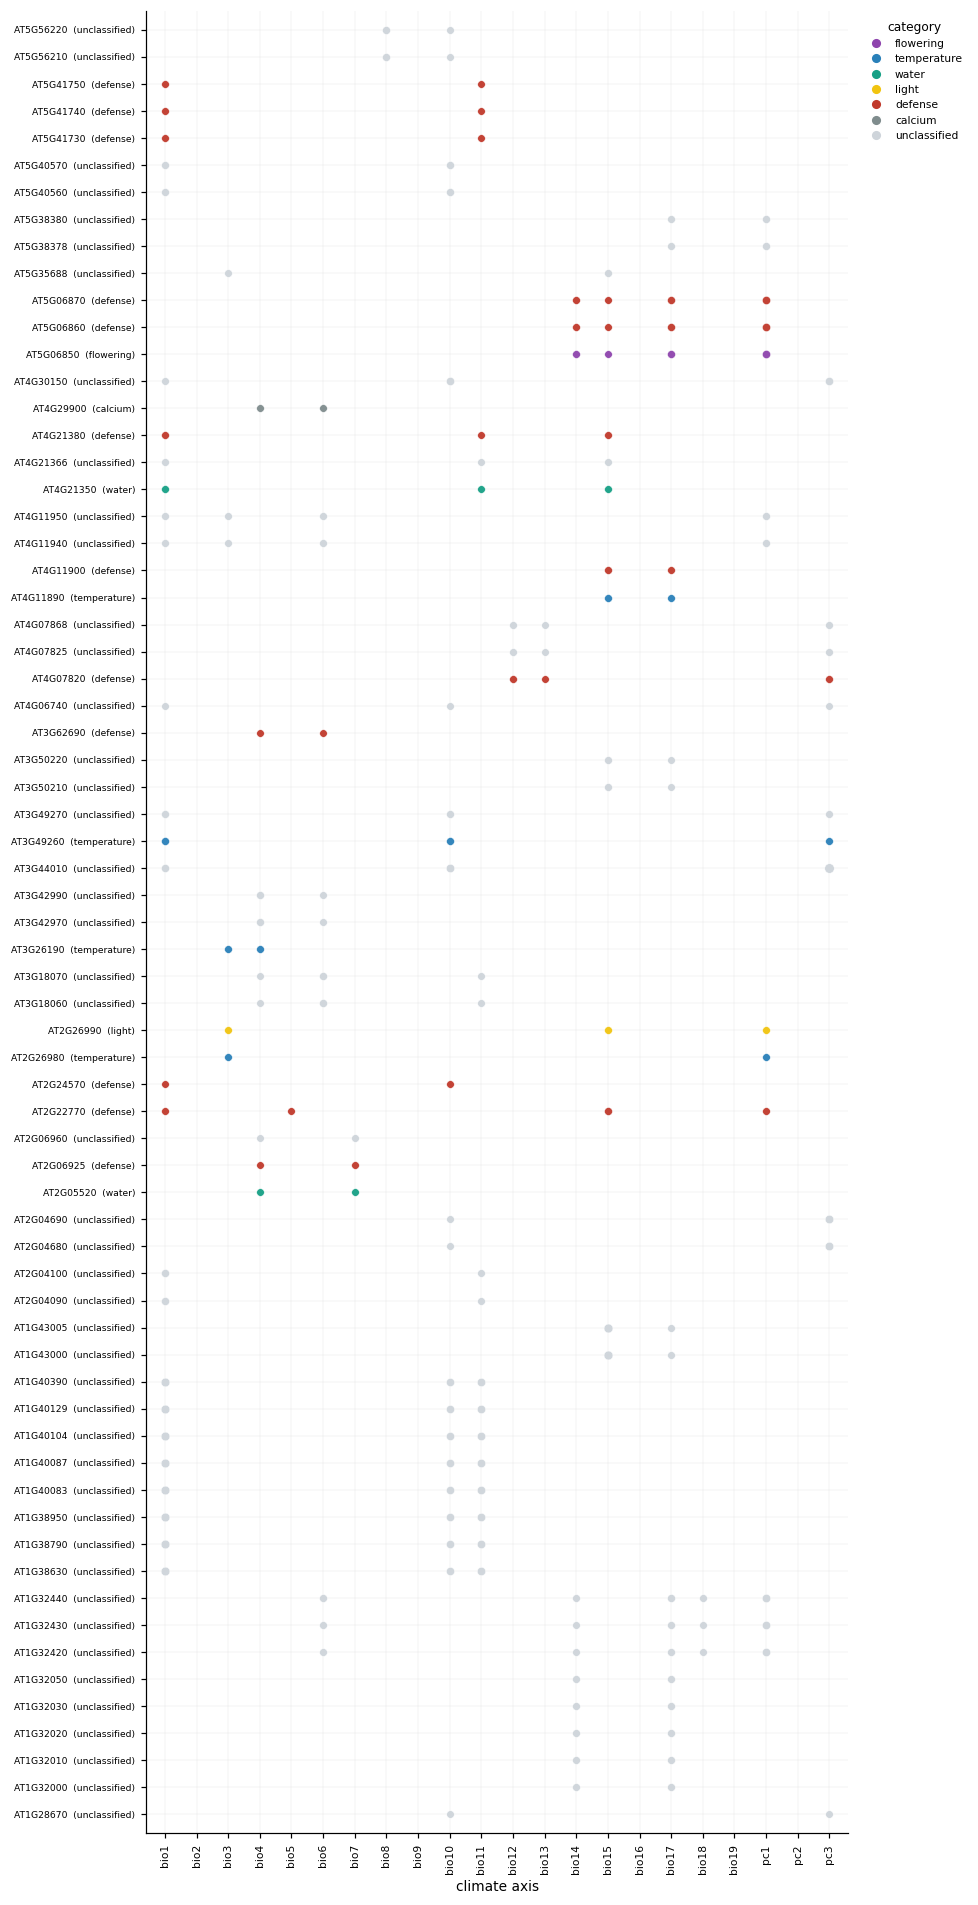

dot plot: 67 genes recurring on >=2 of 22 axes (auto-threshold for legibility); 239 of 306 lower-recurrence genes omitted from the plot but present in the annotated table/CSV.


In [5]:
import matplotlib.lines as mlines

AXES_ORD = [f"bio{i}" for i in range(1, 20)] + ["pc1", "pc2", "pc3"]
_rows = []
if all_newpk:
    for r in pd.concat(all_newpk, ignore_index=True).itertuples():
        for g in (r.genes.split(";") if r.genes else []):
            _rows.append(dict(gene=g, axis=r.axis, nlp=r.nlp, chrom=r.chrom, pos=r.pos))
GX = pd.DataFrame(_rows)

if len(GX):
    _nax = GX.groupby("gene")["axis"].nunique()
    thr = 2
    while int((_nax >= thr).sum()) > 70 and thr < 8:
        thr += 1
    keep_genes = set(_nax[_nax >= thr].index)
    D = GX[GX["gene"].isin(keep_genes)].drop_duplicates(["gene", "axis"]).copy()
    gord = (D.drop_duplicates("gene")
            .assign(_cn=lambda x: x["chrom"].str.replace("Chr", "", regex=False).astype(int))
            .sort_values(["_cn", "pos"])["gene"].tolist())
    catmap = dict(zip(cand_annot["gene"], cand_annot["categories"])) if len(cand_annot) else {}
    symmap = dict(zip(cand_annot["gene"], cand_annot["symbol"])) if len(cand_annot) else {}
    def _pcat(g):
        c = [x for x in (catmap.get(g, "") or "").split(",") if x]
        return c[0] if c else "unclassified"
    CATCOL = {"flowering": "#8E44AD", "temperature": "#2980B9", "water": "#16A085",
              "light": "#F1C40F", "oxidative": "#E67E22", "defense": "#C0392B",
              "calcium": "#7F8C8D", "unclassified": "#CED4DA"}
    yidx = {g: i for i, g in enumerate(gord)}
    xidx = {a: i for i, a in enumerate(AXES_ORD)}
    fig, ax = plt.subplots(figsize=(9, max(4, 0.26 * len(gord))))
    for _, rr in D.iterrows():
        ax.scatter(xidx[rr["axis"]], yidx[rr["gene"]], s=12 + rr["nlp"] * 2.2,
                   c=CATCOL.get(_pcat(rr["gene"]), "#CED4DA"), edgecolors="white",
                   linewidths=0.3, alpha=0.95, zorder=3)
    ax.set_xticks(range(len(AXES_ORD))); ax.set_xticklabels(AXES_ORD, rotation=90, fontsize=7)
    ax.set_yticks(range(len(gord)))
    ax.set_yticklabels([f"{(symmap.get(g) or g)}  ({_pcat(g)})" for g in gord], fontsize=6)
    ax.set_xlim(-0.6, len(AXES_ORD) - 0.4); ax.set_ylim(-0.7, len(gord) - 0.3)
    ax.grid(True, axis="both", lw=0.3, c="0.9", zorder=0); ax.set_axisbelow(True)
    ax.set_xlabel("climate axis", fontsize=9)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    _present = [c for c in CATCOL if c in {_pcat(g) for g in gord}]
    _h = [mlines.Line2D([], [], marker="o", ls="", ms=7, mfc=CATCOL[c], mec="white", label=c)
          for c in _present]
    ax.legend(handles=_h, title="category", loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, title_fontsize=8)
    fig.tight_layout(); plt.show()
    _tot = GX["gene"].nunique()
    print(f"dot plot: {len(gord)} genes recurring on >={thr} of 22 axes "
          f"(auto-threshold for legibility); {_tot - len(gord)} of {_tot} lower-recurrence "
          f"genes omitted from the plot but present in the annotated table/CSV.")
else:
    print("no gene-bearing new peaks to plot")